# Donier LLOB — 데이터부터 실증 결론까지 이해하는 실습 노트북

**읽으면서 이해 → 실제 v4 결과를 시각화 → 필요할 때 실험 전체 재실행**

> 이 노트북은 새로운 시장 성과를 만들어내는 것이 아니라, **사용자가 실제 Deribit 시장 데이터로 실행한 v4 결과**를 읽기 쉽게 재구성한 학습용 버전입니다. 원본 계산 코드는 뒷부분에서 그대로 재실행할 수 있도록 유지했습니다. 재구성된 그래프는 모두 이전 결과 CSV에서 계산하며, 합성 시장 데이터는 사용하지 않습니다.

**질문:** Donier et al. (2015), *A fully consistent, minimal model for non-linear market impact*의 Eq.(9)가 Deribit 가격 반응을 선형 Eq.(10)보다 잘 설명할까? 그 Eq.(9)를 학습 제약으로 추가한 GRU는 일반 GRU보다 실제로 나을까?

**주의:** 공개 거래 체결에는 부모주문 ID가 없습니다. 사건은 진짜 기관 메타오더가 아니라 *동일 방향 순체결이 강한 시간 구간*의 대리표본입니다. 실험에서 구간 전체의 체결을 관측한 후 재구성하므로 실시간 투자 신호가 아닙니다.

## 먼저 전체 지도

| 단계 | 우리가 아는 것 | 계산하는 것 | 결과를 읽는 방법 |
|---|---|---|---|
| A. 데이터 | 실제 L2 호가와 실제 taker 체결 | Midprice, 체결량, 매수·매도 방향 | 어떤 데이터가 직접 관측됐나? |
| B. 사건 추출 | 구간 전체의 체결 기록 | 60·120·300초 방향성 구간 | 진짜 메타오더가 **아님** |
| C. 물리 방정식 | 실제 구간의 서명된 시간별 체결량 | Eq.(10) 선형, Eq.(9) 비선형 충격 | 반사실적 기계충격과 **동일하지 않음** |
| D. 수치 검증 | Eq.(12) 이론적 해, 격자별 계산 | 수렴 오차, 개별 사건 오류 | 수치오류와 모델오류 분리 |
| E. 모델 학습 | Train 기간의 조건부 경로 | 유효 D·L 보정, GRU 가중치 | 물리 제약 ON/OFF 검증 |
| F. 최종 평가 | 독립 Test의 실제 Midprice 경로 | MAE, 수렴률, 물리 잔차 | 비선형 LLOB의 추가가치 판정 |

**권장 사용법:** 아래의 `PART I`만 실행하면 지금 업로드했던 v4 결과를 새로운 그래프로 모두 볼 수 있습니다. 네트워크가 필요하지 않습니다. `PART II`는 처음부터 같은 실험을 다시 실행하고 싶을 때만 사용합니다.

---
# PART I — 실행된 v4 결과 읽어보기

여기부터는 **이전에 업로드한 v4 결과 ZIP의 파생 CSV**를 노트북 안에 압축해서 넣어두었습니다. `Run all`을 눌러도 이 파트는 인터넷에 접속하지 않고 실제 결과표를 읽습니다.

데이터 유래: 2026-08-01 / 09-01 (Train), 10-01 (Validation), 11-01 (Test), BTC-PERPETUAL, UTC 00:00–01:30. 각 월초 하루 90분씩입니다.

시각화를 위한 데이터는 **실제 실행 결과의 통계·파생값**으로, 원시 L2/Trade를 내장한 것이 아닙니다.

In [2]:
import pandas as pd, numpy as np, matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter
import io,base64,zipfile, math
from IPython.display import display
plt.rcParams.update({'figure.figsize':(9,4.8),'axes.grid':True,'grid.alpha':.22,'font.size':11,'axes.titlesize':12,'figure.dpi':110})

def read_existing_results():
    payload=base64.b64decode(_V4_RESULTS_B64)
    with zipfile.ZipFile(io.BytesIO(payload)) as z:
        return {n[:-4]:pd.read_csv(z.open(n)) for n in z.namelist() if n.endswith('.csv')}

RESULT=read_existing_results()
print('실제 v4 결과에서 불러온 테이블:',len(RESULT))
print('메타오더 대리표본',len(RESULT['proxy_events']),'개 | 실제 Test 날짜',RESULT['proxy_events'].query('split=="test"').date_id.unique())

실제 v4 결과에서 불러온 테이블: 19
메타오더 대리표본 422 개 | 실제 Test 날짜 ['2026-11-01']


## 0. 무엇을 학습하고 무엇을 측정했나?

| 종류 | 변수 | 관측/추정 구분 |
|---|---|---|
| 실제 관측 | Midprice, Bid/Ask, 체결시각, 방향, USD 거래량 | 직접 관측 |
| 사건 정의 | 순체결량 `Q_usd`, 총 체결량 `gross_usd`, `dominance`, 사건 길이 `T_s` | 관측 데이터로 만든 **사후 대리변수** |
| 물리 매개변수 | `D_proxy`, `L_effective` | Train으로 **보정**한 가정 의존 계수 |
| 이론 모형 출력 | `Eq10_linear`, `Eq9_full_history`, `Eq12_constant_rate` | 조건부 계산 경로 |
| ML 학습 | GRU 가중치, HGB | Train에서 학습, Val로 선택 |
| 평가 | `path_MAE_bp`, `end_MAE_bp`, 수치 수렴 | 독립 Test에서 계산 |

### 데이터 분할

Train/Val/Test는 각 날짜에 대해 분리되어 있습니다. 하지만 **Test는 11월 1일 90분 한 구간**이므로 시장 전반에 대한 일반화 성능으로 해석할 수 없습니다.

### 그림 1. 사건을 몇 개 확보했을까?

**확인할 질문 —** 실제 데이터로 분석한 60·120·300초 구간이 날짜와 역할별로 얼마나 다른가?

**그래프 읽는 법 —** X축 사건 길이(초), 막대 높이는 구간 수; 색상은 Train/Validation/Test입니다.

**해석 —** 짧은 60초 구간이 가장 많고, 300초 구간은 적습니다. 여러 길이의 사건은 서로 겹칠 수 있어 모두 독립표본은 아닙니다.

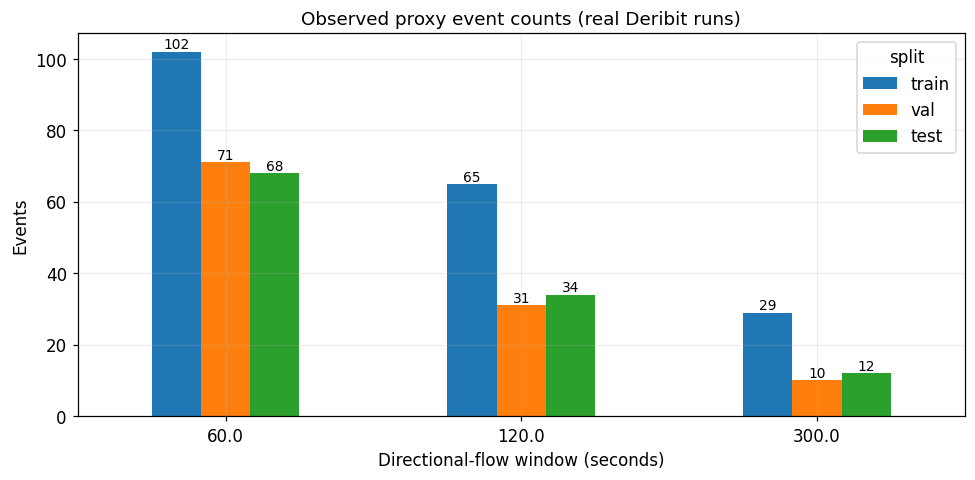

Total selected events: 422  (overlap across window scales is possible)


In [3]:
p=RESULT['proxy_events']
t=(p.groupby(['T_s','split']).size().unstack(fill_value=0)
   .reindex(columns=['train','val','test'],fill_value=0))
ax=t.plot(kind='bar',rot=0,figsize=(9,4.5))
ax.set(xlabel='Directional-flow window (seconds)',ylabel='Events',title='Observed proxy event counts (real Deribit runs)')
for bar in ax.patches:
    if bar.get_height(): ax.annotate(f'{bar.get_height():.0f}',(bar.get_x()+bar.get_width()/2,bar.get_height()),ha='center',va='bottom',fontsize=9)
plt.tight_layout();plt.show()
print('Total selected events:',len(p),' (overlap across window scales is possible)')

### 그림 2. 이 사건을 메타오더라고 볼 수 있을까?

**확인할 질문 —** 구간 내 주문흐름은 얼마나 한쪽 방향으로 몰려 있었는가?

**그래프 읽는 법 —** Dominance = |순체결량| / 총 체결량. 1이면 한 방향, 0이면 매수·매도 균형. 점 하나가 사후 선택된 실제 구간입니다.

**해석 —** Test에서 특히 300초 구간은 방향성이 약합니다. 진짜 부모주문이 아니라는 한계를 그래프로 확인합니다.

**주의 —** 강한 방향성도 특정 투자자의 주문을 식별한다는 뜻은 아닙니다.

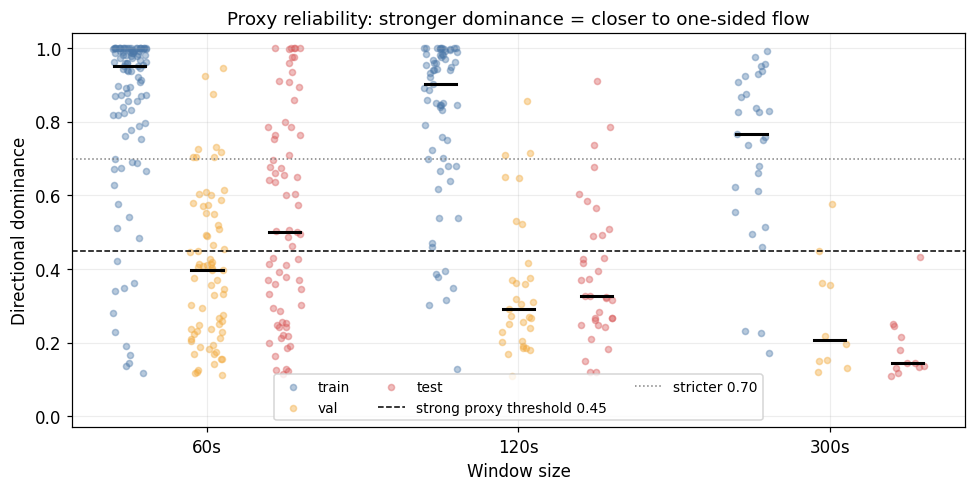

             size  median
split T_s                
test  60.0     68   0.502
      120.0    34   0.326
      300.0    12   0.145
train 60.0    102   0.951
      120.0    65   0.903
      300.0    29   0.767
val   60.0     71   0.398
      120.0    31   0.292
      300.0    10   0.206


In [4]:
p=RESULT['proxy_events']
fig,ax=plt.subplots(figsize=(9,4.6))
cols={'train':'#4c78a8','val':'#f2a93b','test':'#d85a5a'}
for k,sp in enumerate(['train','val','test']):
  for j,T in enumerate([60.,120.,300.]):
    yy=p.loc[(p.split==sp)&(p.T_s==T),'dominance'].to_numpy()
    if not len(yy):continue
    xx=np.full(len(yy),j)+(-.25+k*.25)+np.random.default_rng(51+j+k*10).uniform(-.055,.055,len(yy))
    ax.scatter(xx,yy,s=16,alpha=.4,color=cols[sp],label=sp if j==0 else None)
    ax.plot([j-.3+k*.25,j-.2+k*.25],[np.median(yy)]*2,color='black',lw=2)
ax.axhline(.45,color='black',ls='--',lw=1,label='strong proxy threshold 0.45')
ax.axhline(.70,color='grey',ls=':',lw=1,label='stricter 0.70')
ax.set(xticks=range(3),xticklabels=['60s','120s','300s'],ylim=(-.03,1.04),ylabel='Directional dominance',xlabel='Window size',title='Proxy reliability: stronger dominance = closer to one-sided flow')
ax.legend(ncol=3,fontsize=9);plt.tight_layout();plt.show()
print(p.groupby(['split','T_s']).dominance.agg(['size','median']).round(3).to_string())

## 1. 왜 Eq.(9)과 Eq.(10)을 비교하나?

원 논문은 **가격을 움직이기 전의 잠재 유동성이 가격 부근에서 선형**이라고 가정합니다.

\[
\varphi(x,t)=\rho_B(x,t)-\rho_A(x,t),\qquad \varphi(p_t,t)=0
\]

그 결과 외생적 메타오더의 가격 충격 \(y_t\)가 다음 관계를 따른다고 제안합니다.

**Eq.(9) — 비선형 자기일관 식:**

\[
y_t=\frac{1}{\mathcal L}\int_0^t
\frac{m_s}{\sqrt{4\pi D(t-s)}}
\exp\left[-\frac{(y_t-y_s)^2}{4D(t-s)}\right]ds
\]

**Eq.(10) — 충격이 작은 경우:** 지수 함수가 약 1이므로

\[
y_t\approx\frac{1}{\mathcal L}\int_0^t\frac{m_s}{\sqrt{4\pi D(t-s)}}ds.
\]

| 기호 | 의미 | 지금 어떻게 구했나? |
|---|---|---|
| \(m_s\) | 원 논문의 외생적 메타오더 집행속도 | **대신** 실제 시장 전체의 순매수/순매도 흐름을 사용 (엄밀히 다름) |
| \(D\) | 잠재 의향의 가격축 확산계수 | 학습일의 Midprice 변동성으로 **대체** |
| \(\mathcal L\) | 잠재 유동성 기울기 | Train 사건에 맞도록 **유효값 보정** |
| \(y_t\) | 무충격 기준가격 대비 기계적 충격 | 실제로는 관측가격의 방향보정 변화와 비교 (동일하지 않음) |

따라서 **수학적으로 식을 정확히 풀었다**와 **시장에서 그 식이 인과적으로 맞았다**는 다른 질문입니다.

### 그림 3. 이론식을 정확하게 계산했을까?

**확인할 질문 —** 같은 일정 속도 거래를 넣었을 때 Eq.(9) 수치해가 Eq.(12)의 알려진 이론해에 가까워지는가?

**그래프 읽는 법 —** X축 분할 수 N, Y축 상대오차(%). 내려갈수록 좋은 수치 수렴입니다.

**해석 —** N 증가에 따라 상대오차가 감소하므로 일정속도 예제에서는 해법이 작동합니다. 실제 거래 적합도 증명은 아닙니다.

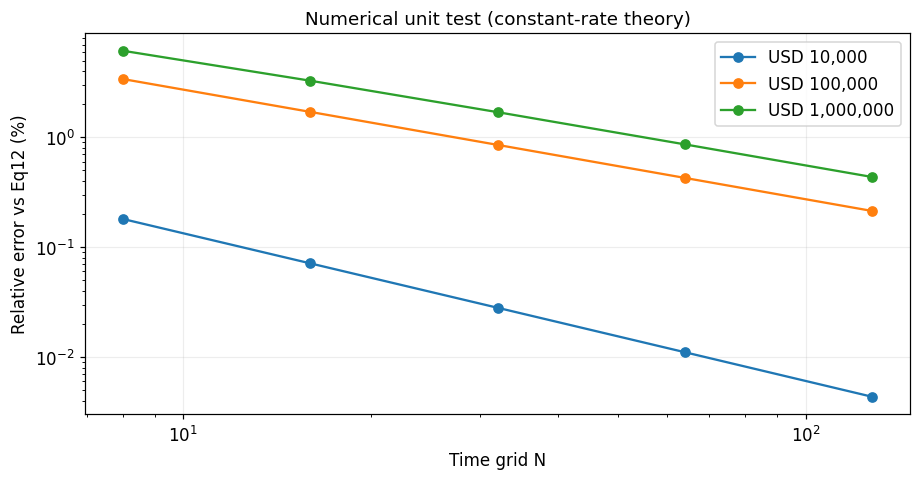

Theoretical unit test: these numbers are NOT market validation.


In [5]:
c=RESULT['eq9_eq12_convergence']
fig,ax=plt.subplots(figsize=(8.5,4.5))
for Q,g in c.groupby('Q_usd'):
    ax.plot(g.N,g.rel_error*100,'o-',label=f'USD {Q:,.0f}')
ax.set(xscale='log',yscale='log',xlabel='Time grid N',ylabel='Relative error vs Eq12 (%)',title='Numerical unit test (constant-rate theory)')
ax.legend();plt.tight_layout();plt.show()
print('Theoretical unit test: these numbers are NOT market validation.')

### 그림 4. 실제 불규칙 거래에서도 계산이 안정적인가?

**확인할 질문 —** 같은 거래를 32, 64, 128, 256분할로 계산하면 사실상 같은 결과로 수렴하는가?

**그래프 읽는 법 —** 왼쪽은 실제 Test 사건별 coarse vs refined 종료충격, 점선은 일치선. 오른쪽은 사건 길이별 수렴 통과 비율입니다.

**해석 —** 일정속도 이론해와 달리 실제 사건에서는 격자 민감도가 매우 큽니다. **수치해법 실패를 LLOB 이론 실패로 오해하지 말아야** 합니다.

**주의 —** 성공한 근찾기(`solver_health.success`)는 격자 수렴을 보증하지 않습니다. 오른쪽 비율은 대표 30건에 한정됩니다.

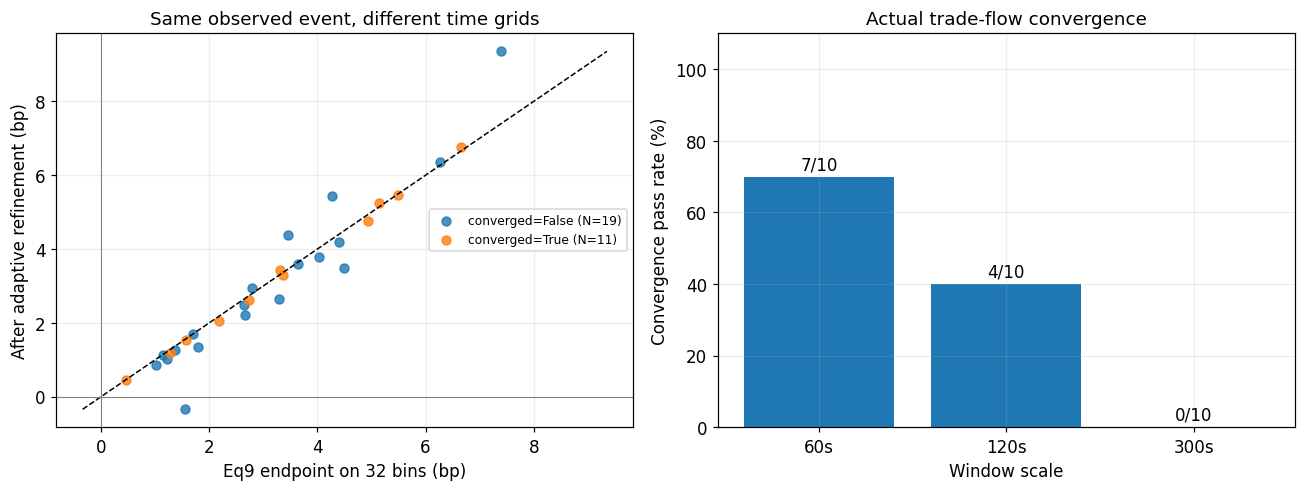

Total 11 / 30 converged (sampled events only)


In [6]:
r=RESULT['observed_trade_timegrid_refinement'].copy()
fig,(a,b)=plt.subplots(1,2,figsize=(12,4.6))
for flag,g in r.groupby('converged'):
    a.scatter(g.endpoint_N32,g.endpoint_refined,label=f'converged={flag} (N={len(g)})',alpha=.8,s=34)
lo=np.nanmin(r[['endpoint_N32','endpoint_refined']].values);hi=np.nanmax(r[['endpoint_N32','endpoint_refined']].values)
a.plot([lo,hi],[lo,hi],'k--',lw=1)
a.axhline(0,color='grey',lw=.7);a.axvline(0,color='grey',lw=.7)
a.set(xlabel='Eq9 endpoint on 32 bins (bp)',ylabel='After adaptive refinement (bp)',title='Same observed event, different time grids');a.legend(fontsize=8)
q=r.groupby('T_s').converged.agg(['sum','count']);q['rate']=q['sum']/q['count']
b.bar([str(int(x))+'s' for x in q.index],q['rate']*100)
for j,rr in enumerate(q.itertuples()): b.text(j,rr.rate*100+2,f'{int(rr.sum)}/{rr.count}',ha='center')
b.set(ylim=(0,110),ylabel='Convergence pass rate (%)',xlabel='Window scale',title='Actual trade-flow convergence')
plt.tight_layout();plt.show()
print('Total',int(r.converged.sum()),'/',len(r),'converged (sampled events only)')

## 2. 무엇을 학습했나? 계수와 신경망 구분하기

**A. 모형 계수 보정:** 원 논문의 \(D\)와 \(\mathcal L\)을 실측한 것이 아닙니다. 현재 구현에서는 Train의 1초 Midprice 변동성으로 `D_proxy`를 정하고, Eq.(9)·Eq.(10)·Eq.(12)의 각각 다른 유효 `L`을 Train의 종가 오차로 보정합니다.

**B. 신경망 학습:** 같은 GRU에 실제 주문흐름과 Eq.(10) 경로를 입력합니다. Plain은 가격 경로 오차만 최소화하고, Physics GRU는 Eq.(9) 적분 잔차를 추가로 줄입니다.

**C. 검증과 테스트:** Validation(10월)에서 최적 Epoch과 Physics 가중치를 고르고, Test(11월)에서 오차를 계산합니다.

### 그림 5. 모델별 유효 유동성 \(\mathcal L\)은 얼마인가?

**확인할 질문 —** 같은 데이터에서도 Eq9/Eq10/Eq12가 서로 다른 계수를 필요로 하는가?

**그래프 읽는 법 —** 막대는 Train에서 보정된 유효 L입니다. D는 모두 가격변동 분산의 대리변수입니다.

**해석 —** 계수 추정 결과의 차이는 모형 가정과 보정 목적의 차이를 보여줍니다. **잠재 주문장 기울기의 실측값이 아닙니다.**

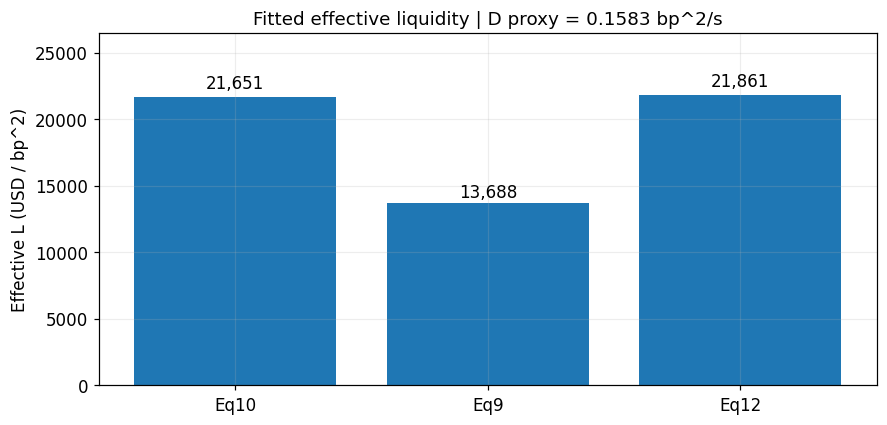

model  train_pseudo_huber  near_bound
 Eq10            3.047692       False
  Eq9            2.950484       False
 Eq12            3.084622       False


In [7]:
p=RESULT['train_parameter_calibration']
fig,ax=plt.subplots(figsize=(8.2,4))
ax.bar(p.model,p.L_effective_USD_bp2)
for i,val in enumerate(p.L_effective_USD_bp2):ax.text(i,val*1.03,f'{val:,.0f}',ha='center')
ax.set(ylabel='Effective L (USD / bp^2)',title=f'Fitted effective liquidity | D proxy = {p.D_proxy_bp2_s.iloc[0]:.4f} bp^2/s',ylim=(0,p.L_effective_USD_bp2.max()*1.21))
plt.tight_layout();plt.show()
print(p[['model','train_pseudo_huber','near_bound']].to_string(index=False))

### 그림 6. GRU는 실제로 학습된 모델이 선택됐을까?

**확인할 질문 —** Epoch을 늘릴수록 Validation의 예측오차가 줄어드는가?

**그래프 읽는 법 —** X축 Epoch, Y축 10월 Validation 경로 MAE(bp). 물리 손실 가중치가 다른 세 곡선을 비교합니다.

**해석 —** 이번 실행은 세 모델 모두 최적 Epoch이 0입니다. **결국 학습 전 Eq.(10) 초기 모델로 돌아갔다는 뜻**입니다.

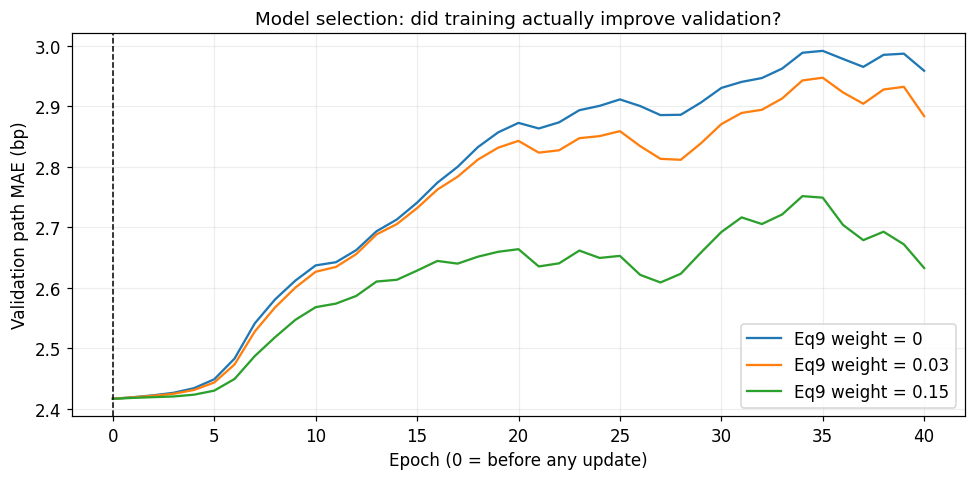

 weight  best_epoch  val_MAE_bp  initial_val_MAE_bp
   0.00           0    2.416552            2.416552
   0.03           0    2.416552            2.416552
   0.15           0    2.416552            2.416552


In [8]:
h=RESULT['nn_training_history'];sel=RESULT['nn_validation_selection']
fig,ax=plt.subplots(figsize=(9,4.5))
for w,g in h.groupby('physics_weight'):
    ax.plot(g.epoch,g.val_MAE_bp,label=f'Eq9 weight = {w:g}')
ax.axvline(0,color='black',ls='--',lw=1)
ax.set(xlabel='Epoch (0 = before any update)',ylabel='Validation path MAE (bp)',title='Model selection: did training actually improve validation?')
ax.legend();plt.tight_layout();plt.show()
print(sel[['weight','best_epoch','val_MAE_bp','initial_val_MAE_bp']].to_string(index=False))

### 그림 7. 물리 방정식에 더 잘 맞으면 실제가격도 더 잘 맞나?

**확인할 질문 —** 물리 잔차가 감소해도 Validation 가격경로 오차가 줄어들지 않을 수 있나?

**그래프 읽는 법 —** X축 Epoch, Y축 학습 데이터의 Eq.(9) residual MSE. 로그축에서 내려가면 제약을 잘 만족합니다.

**해석 —** 물리 잔차의 감소는 모델 내부 정합성 향상이지 실거래에서 정확해졌다는 증거가 아닙니다. 그림 6과 함께 봐야 합니다.

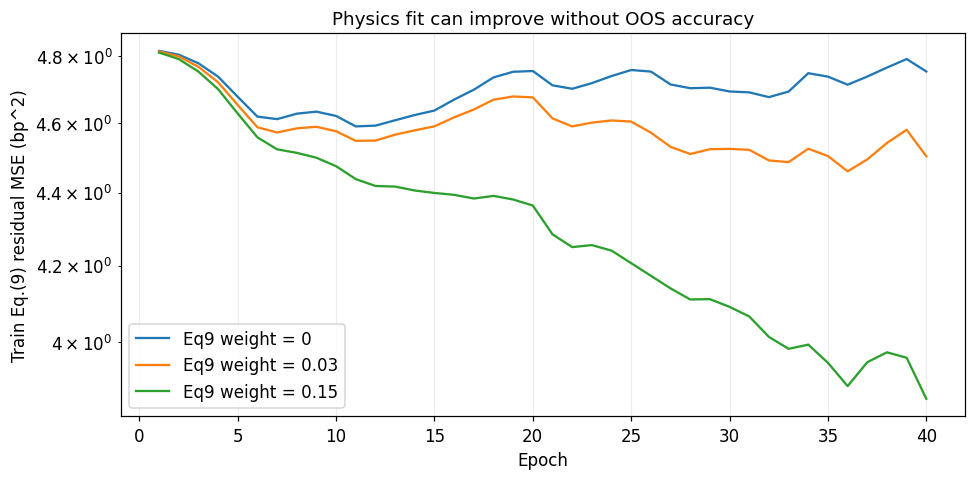

In [9]:
h=RESULT['nn_training_history']
fig,ax=plt.subplots(figsize=(9,4.5))
for w,g in h.groupby('physics_weight'):
    g=g[(g.epoch>0)&np.isfinite(g.train_phys_MSE)&(g.train_phys_MSE>0)]
    ax.plot(g.epoch,g.train_phys_MSE,label=f'Eq9 weight = {w:g}')
ax.set(xlabel='Epoch',ylabel='Train Eq.(9) residual MSE (bp^2)',yscale='log',title='Physics fit can improve without OOS accuracy')
ax.legend();plt.tight_layout();plt.show()

## 3. 실제 Test에서 어떤 모형이 더 정확했나?

여기서는 **조건부 과거 경로 재구성**입니다. 사건이 끝나야 그 구간의 총 체결량과 시간별 체결흐름을 알 수 있습니다. 사전 트레이딩 전략이나 새로운 가격을 예측한 결과라고 쓰면 안 됩니다.

- **경로 MAE:** 한 사건 내 여러 시점의 가격 변화 오차 평균
- **종료 MAE:** 사건 종료시점 한 가격의 오차
- **Coverage:** 해당 모델이 계산 가능한 사건의 비율 (수치적 수렴 검증 통과 비율과는 다릅니다)

### 그림 8. 120초 Test 모형별 경로 예측오차

**확인할 질문 —** Eq.(9)보다 Eq.(10)이 나은가? GRU가 무엇을 개선했는가?

**그래프 읽는 법 —** MAE(bp)가 낮을수록 좋습니다. Endpoint-only HGB는 경로를 예측하지 않아 제외합니다.

**해석 —** 이 Test에서 Zero Impact의 평균 경로오차가 가장 작고 Eq9가 Eq10보다 큽니다. 이는 현재 대리표본과 계수에 대한 결과이며 이론 자체를 반박한 것은 아닙니다.

**주의 —** 비선형 Eq9의 높은 오차에는 수치 수렴 불확실성도 포함되어 있습니다.

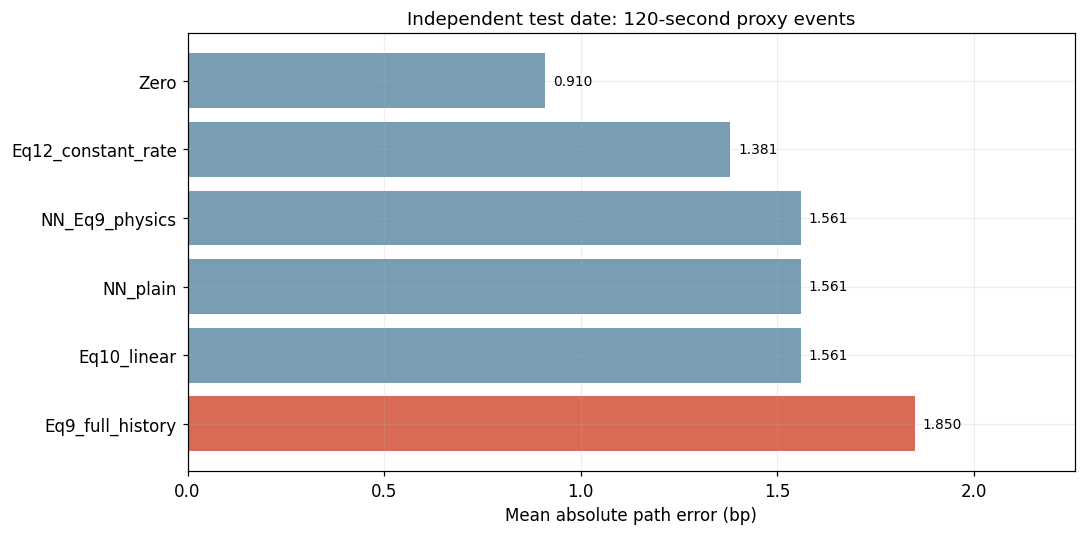

             model  N  N_evaluated  coverage  path_MAE_bp  end_MAE_bp
              Zero 34           34       1.0     0.910216    1.602738
Eq12_constant_rate 34           34       1.0     1.381089    1.638568
    NN_Eq9_physics 34           34       1.0     1.560589    1.750710
          NN_plain 34           34       1.0     1.560589    1.750710
       Eq10_linear 34           34       1.0     1.560589    1.750710
  Eq9_full_history 34           34       1.0     1.850274    2.052528


In [10]:
m=RESULT['model_scores'].query('split=="test" and T_s==120').dropna(subset=['path_MAE_bp']).sort_values('path_MAE_bp')
fig,ax=plt.subplots(figsize=(10,5))
b= ax.barh(m.model,m.path_MAE_bp,color=['#789db4' if x!='Eq9_full_history' else '#d96a56' for x in m.model]);ax.invert_yaxis()
for p in b:ax.text(p.get_width()+.02,p.get_y()+p.get_height()/2,f'{p.get_width():.3f}',va='center',fontsize=9)
ax.set(xlabel='Mean absolute path error (bp)',title='Independent test date: 120-second proxy events',xlim=(0,m.path_MAE_bp.max()*1.22))
plt.tight_layout();plt.show()
print(m[['model','N','N_evaluated','coverage','path_MAE_bp','end_MAE_bp']].to_string(index=False))

### 그림 9. 사건별로 Eq.(9)이 이겼나, Eq.(10)이 이겼나?

**확인할 질문 —** 평균 MAE 뒤에 숨은 사건별 패턴은 무엇인가?

**그래프 읽는 법 —** 점 하나가 120초 Test 사건 하나. x는 Eq10 오차, y는 Eq9 오차. 대각선 아래이면 Eq9가 더 정확합니다.

**해석 —** 개별 사건에서 비선형성이 유리한 사례가 있는지 확인하지만, 격자 불수렴 사건도 포함되어 있어 승패를 과도하게 해석하지 않습니다.

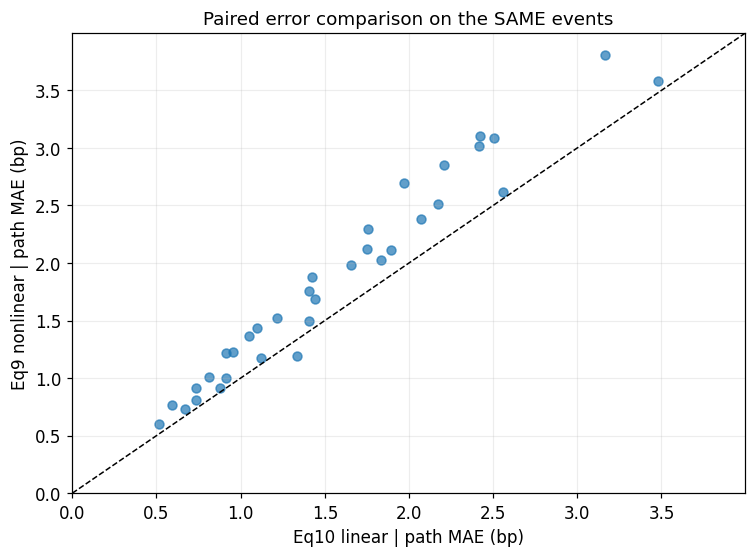

Eq9 lower error: 1/34 events; mean Eq9-Eq10 MAE: +0.290 bp


In [11]:
v=RESULT['event_level_model_scores']
a=v.query('split=="test" and T_s==120 and model=="Eq10_linear"')[['event_id','path_MAE_bp']].rename(columns={'path_MAE_bp':'linear'})
b=v.query('split=="test" and T_s==120 and model=="Eq9_full_history"')[['event_id','path_MAE_bp']].rename(columns={'path_MAE_bp':'nonlinear'})
p=a.merge(b,on='event_id').dropna()
fig,ax=plt.subplots(figsize=(7,5.2));ax.scatter(p.linear,p.nonlinear,s=34,alpha=.7)
hi=max(p[['linear','nonlinear']].to_numpy().max(),.1)*1.05
ax.plot([0,hi],[0,hi],'k--',lw=1)
ax.set(xlim=(0,hi),ylim=(0,hi),xlabel='Eq10 linear | path MAE (bp)',ylabel='Eq9 nonlinear | path MAE (bp)',title='Paired error comparison on the SAME events')
plt.tight_layout();plt.show()
print(f'Eq9 lower error: {(p.nonlinear<p.linear).sum()}/{len(p)} events; mean Eq9-Eq10 MAE: {(p.nonlinear-p.linear).mean():+.3f} bp')

### 그림 10. 사건 길이가 길어지면 모형 성능은?

**확인할 질문 —** 60초·120초·300초에서 선형과 비선형의 오차 차이가 일관적인가?

**그래프 읽는 법 —** X축 사건 길이, Y축 Test 경로 MAE; 같은 모델을 서로 다른 사건집단에서 비교합니다.

**해석 —** 다른 길이의 사건은 표본도 다르고 겹칠 수도 있어, 순수하게 기간만 바꿨을 때의 인과효과로 해석해서는 안 됩니다.

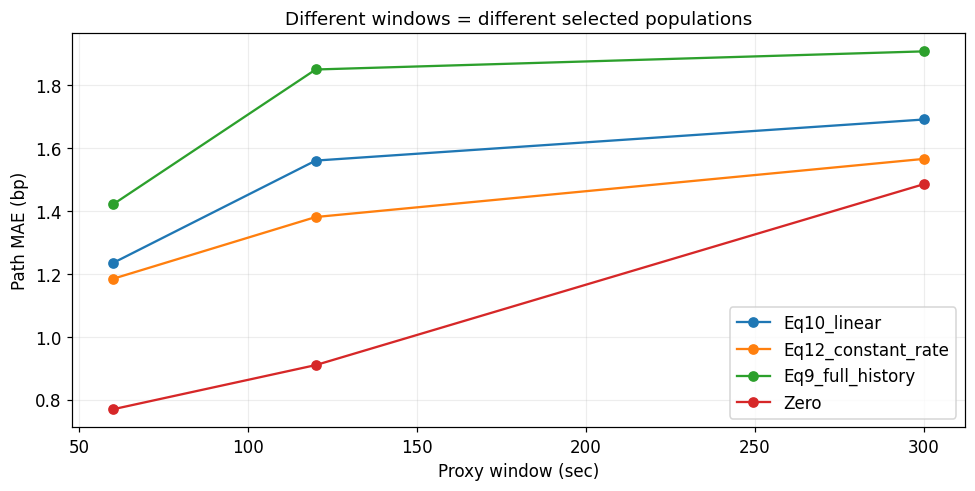

In [12]:
z=RESULT['model_scores'].query('split=="test" and model in ["Zero","Eq10_linear","Eq9_full_history","Eq12_constant_rate"]')
fig,ax=plt.subplots(figsize=(9,4.6))
for name,g in z.groupby('model'):
    ax.plot(g.T_s,g.path_MAE_bp,'o-',label=name)
ax.set(xlabel='Proxy window (sec)',ylabel='Path MAE (bp)',title='Different windows = different selected populations')
ax.legend();plt.tight_layout();plt.show()

### 그림 11. 진짜 비선형 영역을 검사했나?

**확인할 질문 —** 원 논문의 고강도 조건 \(m/J \gg 1\)에 해당하는 사건이 실제로 존재하는가?

**그래프 읽는 법 —** 그룹별 실험 내부의 `rate_model>1`과 `>10` 비율을 표시합니다. 이는 보정된 D·L로 만든 모델 상대강도입니다.

**해석 —** Test에서 >10 강도 사건이 없습니다. 그러므로 고강도에서 비선형 Eq9가 선형보다 우월한지 직접 판정할 수 없습니다.

**주의 —** 원 논문의 J는 느린 잠재 유동성 유입으로, 위 계산의 관측 대리 강도와 정확히 같지 않습니다.

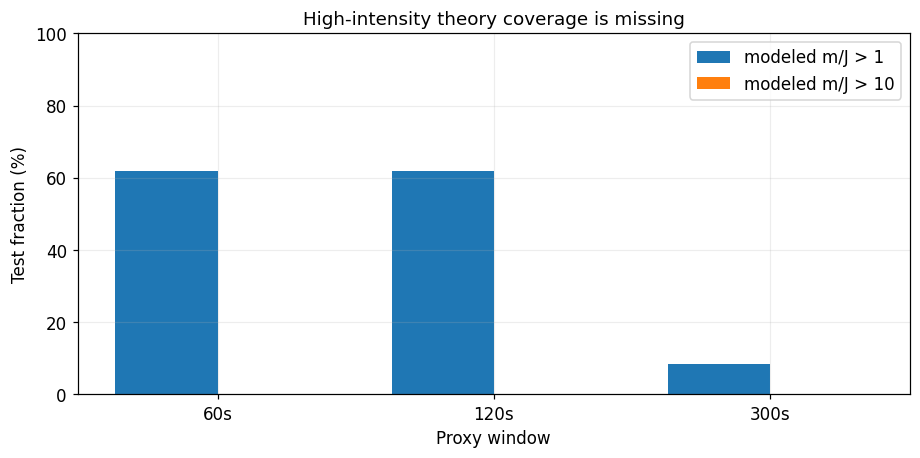

  T_s  N  median_rate_model  pct_above1  pct_above10  strong_share
 60.0 68              1.417       0.618          0.0         0.559
120.0 34              1.181       0.618          0.0         0.294
300.0 12              0.686       0.083          0.0         0.000


In [13]:
z=RESULT['effective_intensity_coverage'];z=z[z.split=='test'].sort_values('T_s')
fig,ax=plt.subplots(figsize=(8.5,4.3));x=np.arange(len(z));w=.37
ax.bar(x-w/2,z.pct_above1*100,w,label='modeled m/J > 1')
ax.bar(x+w/2,z.pct_above10*100,w,label='modeled m/J > 10')
ax.set(xticks=x,xticklabels=[str(int(t))+'s' for t in z.T_s],ylim=(0,100),xlabel='Proxy window',ylabel='Test fraction (%)',title='High-intensity theory coverage is missing')
ax.legend();plt.tight_layout();plt.show()
print(z[['T_s','N','median_rate_model','pct_above1','pct_above10','strong_share']].round(3).to_string(index=False))

### 그림 12. 거래량이 크면 더 많이 움직이는가?

**확인할 질문 —** 방향보정 가격 변화와 순체결 거래량 사이에 경험적 관계가 있나?

**그래프 읽는 법 —** X축 순체결량(로그), Y축 구간별 평균 방향보정 Midprice 변화(bp)입니다.

**해석 —** 연관성이 보이더라도 이 그래프는 \(I(Q)\propto\sqrt Q\)의 인과적 증거가 아닙니다. 집행기간·변동성·정보충격이 혼합돼 있습니다.

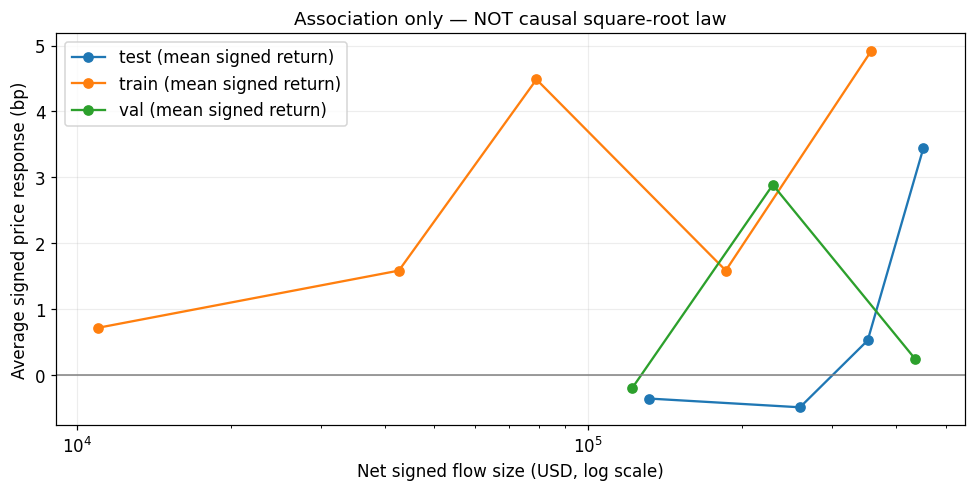

In [14]:
z=RESULT['impact_volume_bins'].query('T_s==120')
fig,ax=plt.subplots(figsize=(9,4.6))
for sp,g in z.groupby('split'):
    ax.plot(g.median_Q,g.avg_signed_price_bp,'o-',label=f'{sp} (mean signed return)')
ax.axhline(0,color='grey',lw=1)
ax.set(xscale='log',xlabel='Net signed flow size (USD, log scale)',ylabel='Average signed price response (bp)',title='Association only — NOT causal square-root law')
ax.legend();plt.tight_layout();plt.show()

### 그림 13. 거래가 끝난 뒤 가격충격이 사라졌나?

**확인할 질문 —** 관측된 종료 후 가격 변화가 이론의 기계적 감쇠식 Eq.(17)을 따르는가?

**그래프 읽는 법 —** X축 종료시간으로 정규화한 t/T; 1은 사건 종료. Y축 종료시 반응으로 나눈 관측 반응의 중앙값입니다.

**해석 —** 실제 응답에는 신규 거래·정보효과가 섞입니다. 이론선과 다른 것이 곧바로 반증이라는 뜻은 아닙니다.

**주의 —** 작은 종료시 반응으로 나누면 비율이 크게 흔들립니다. 기준가격의 반사실적 경로를 알 수 없습니다.

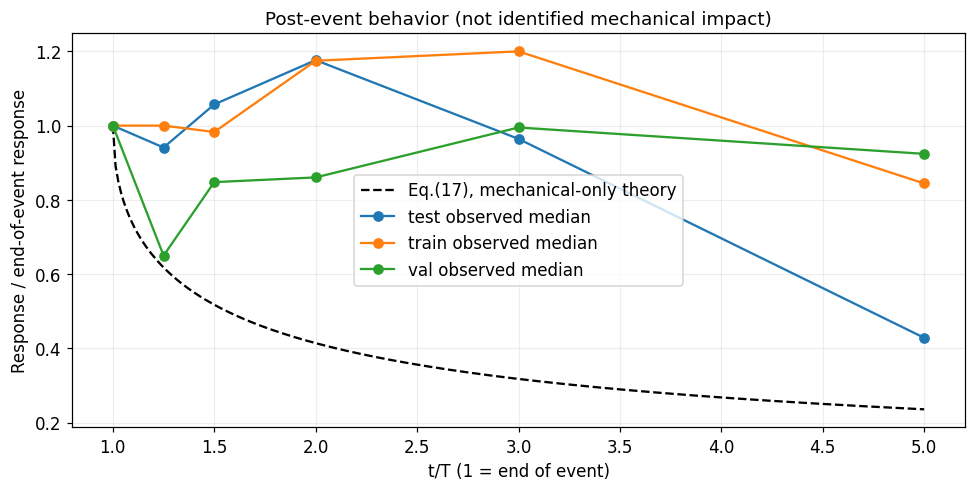

 ratio  count  median
  1.00     19   1.000
  1.25     18   0.941
  1.50     18   1.057
  2.00     18   1.176
  3.00     18   0.964
  5.00     18   0.429


In [15]:
z=RESULT['decay_profiles']
fig,ax=plt.subplots(figsize=(9,4.6))
t=np.linspace(1,5,300);ax.plot(t,np.sqrt(t)-np.sqrt(t-1),'k--',label='Eq.(17), mechanical-only theory')
for sp,g in z.groupby('split'):
    ax.plot(g.ratio,g['median'],'o-',label=f'{sp} observed median')
ax.set(xlabel='t/T (1 = end of event)',ylabel='Response / end-of-event response',title='Post-event behavior (not identified mechanical impact)')
ax.legend();plt.tight_layout();plt.show()
print(z[z.split=='test'][['ratio','count','median']].round(3).to_string(index=False))

## 4. 지금까지의 결과를 한 문장으로

**현재 결과:** 일정속도 메타오더의 수치해는 이론해에 수렴했습니다. 그러나 실제 불규칙 주문흐름에서는 대부분의 대표 사건이 충분히 수렴하지 않았습니다. 독립 Test에서 Eq.(9)은 Eq.(10)보다 낮은 오차를 보이지 못했고, Physics GRU는 검증오차가 학습 중 악화돼 **Epoch 0**의 선형 기본모형을 채택했습니다.

따라서 **Donier의 비선형 LLOB 이론이 실증적으로 입증됐다**고 말할 수 없습니다. 반대로 이론이 틀렸다고 단정할 근거도 부족합니다.

- **수치해의 정확성**, **가정에 맞는 메타오더 표본**, **물리 제약으로 얻은 일반화 개선**은 서로 독립적인 검증 단계입니다.
- 먼저 시간격자 불수렴 사건을 해결하고, 강한 방향성의 60초 사건에 집중한 뒤 충분한 여러 테스트 날짜로 확장하는 것이 좋습니다.
- 물리적 해석을 하기 전에 종속변수(사건 내 가격 변화)가 관측값과 무엇이 다른지 항상 확인해야 합니다.

---
# PART II — 실험 코드를 처음부터 재실행하기 (선택 사항)

**이 파트는 원본 v4의 실제 데이터 다운로드·사건 추출·식 (9) 해법·계수 보정·GRU 학습·통계 검정을 그대로 재현**합니다. 읽기만 할 때는 재실행할 필요가 없습니다.

다음 셀을 `RUN_FULL_RESEARCH=True`로 바꾸고 위에서부터 모두 실행하면 됩니다. 실제 Tardis 서버 접속이 필요하고 원시 CSV가 없으면 가짜 데이터로 대체하지 않습니다.

함수 정의처럼 긴 코드는 기본적으로 접어두었습니다. **중요한 것은 각 단계의 입력과 출력**이므로 순서대로 세부사항을 확인하면 됩니다.

In [16]:
RUN_FULL_RESEARCH = False  # 실제 CSV 수집 + 모든 학습을 재실행할 때만 True
print('Full research:', RUN_FULL_RESEARCH, '| Existing v4 evidence above is available without rerun.')

Full research: False | Existing v4 evidence above is available without rerun.


## R1. 실험 설정 — 날짜·시간척도·수치격자

**입력:** 데이터 날짜, 후보 길이, 최소 거래량과 방향성, Eq9 적분 격자

**출력:** 분석 조건과 저장 경로. 연구 조건을 바꿨으면 각 결과표의 수치가 달라지는 것이 정상입니다.

In [17]:
if RUN_FULL_RESEARCH:
    import os, io, csv, gzip, json, math, random, warnings, zipfile, time
    from pathlib import Path
    from copy import deepcopy
    import requests
    import numpy as np
    import pandas as pd
    import matplotlib.pyplot as plt
    from scipy.optimize import brentq, minimize_scalar
    from scipy.special import erf, ndtr
    from sklearn.preprocessing import StandardScaler
    from sklearn.ensemble import HistGradientBoostingRegressor
    from sklearn.metrics import mean_absolute_error
    import torch
    from torch import nn
    from torch.nn import functional as F

    SEED=14120141
    random.seed(SEED);np.random.seed(SEED);torch.manual_seed(SEED)
    DEVICE='cuda' if torch.cuda.is_available() else 'cpu'
    TRAIN_DATES=['2026-08-01','2026-09-01']
    VAL_DATES=['2026-10-01']; TEST_DATES=['2026-11-01']
    DATES=TRAIN_DATES+VAL_DATES+TEST_DATES
    EXCHANGE='deribit'; SYMBOL='BTC-PERPETUAL'
    START_UTC_HOUR=0; MINUTES_PER_DAY=90
    WINDOW_SCALES=(60,120,300); PRIMARY_WINDOW_S=120
    CANDIDATE_STEP_S=15; MIN_TRADES=5; MIN_GROSS_USD=10_000.
    MIN_NET_USD=2_000.; MIN_DOMINANCE=0.10
    N_GRID=32; FLOW_SIGMA_S=2.0  # Gaussian coarse-graining, fixed in PHYSICAL seconds
    QUOTE_MAX_AGE_S=8.; QUOTE_START_MAX_AGE_S=8.
    MAX_ROWS_PER_FILE=9_000_000
    QUAD_ORDER=14
    CALIBRATION_MAX=45
    REFINE_FACTORS=(1,2,4)
    REFINE_ABS_TOL_BP=0.08
    REFINE_REL_TOL=0.05
    MAX_REFINE_EVENTS=30  # sample for full refinement diagnostic; representative by activity and date
    RUN_PINN=True
    NN_EPOCHS=180; NN_BATCH_SIZE=24; NN_LR=0.0006
    NN_PATIENCE=30; NN_PHYS_WEIGHTS=(0.03,0.15)
    NN_HIDDEN=48
    BOOTSTRAP_REPS=300
    OUT=Path('/content/Donier_LLOB_Empirical_v4') if Path('/content').exists() else Path('/mnt/data/Donier_LLOB_Empirical_v4')
    OUT.mkdir(exist_ok=True,parents=True)
    CACHE=OUT/'private_raw_cache';CACHE.mkdir(exist_ok=True)
    assert max(TRAIN_DATES)<min(VAL_DATES) and max(VAL_DATES)<min(TEST_DATES)
    print('Device:',DEVICE,' | output:',OUT)
    print('Data:',DATES,'; NO synthesized/replacement data in research notebook')
    print('Interpretation: ex-post conditional reconstruction, NOT identified causal metaorder impact.')

## R2. 실제 데이터 다운로드 — L2·Trade

**입력:** Tardis의 Deribit BTC-PERPETUAL CSV

**출력:** `market[day] = (book, trades)`; 호가 Midprice와 시장가성 매수/매도 거래시각·USD 계약수량. 인터넷 오류 시 합성 데이터로 대체하지 않습니다.

In [18]:
if RUN_FULL_RESEARCH:
    def stream_csv(day, data_type):
        yyyy,mm,dd=day.split('-')
        url=f'https://datasets.tardis.dev/v1/{EXCHANGE}/{data_type}/{yyyy}/{mm}/{dd}/{SYMBOL}.csv.gz'
        print('GET',url)
        with requests.get(url,stream=True,timeout=(30,240),headers={'User-Agent':'academic-donier-eq9-study/2.0'}) as response:
            response.raise_for_status()
            response.raw.decode_content=False
            with gzip.GzipFile(fileobj=response.raw) as gz:
                rd=csv.DictReader(io.TextIOWrapper(gz,encoding='utf-8',newline=''))
                for idx,row in enumerate(rd):
                    if idx>=MAX_ROWS_PER_FILE:
                        raise RuntimeError('MAX_ROWS_PER_FILE reached; dataset incomplete, aborting.')
                    yield row

    def time_limits(day):
        start=pd.Timestamp(day,tz='UTC')+pd.Timedelta(hours=START_UTC_HOUR)
        return int(start.value//1000),int((start+pd.Timedelta(minutes=MINUTES_PER_DAY)).value//1000)

    def load_market_day(day):
        bpfile=CACHE/f'{day}_book.pkl';trfile=CACHE/f'{day}_trades.pkl'
        if bpfile.exists() and trfile.exists():
            book=pd.read_pickle(bpfile);tr=pd.read_pickle(trfile)
            if len(book)>100 and len(tr)>20:
                print(day,'using local real-data cache:',len(book),len(tr))
                return book,tr
        start,end=time_limits(day)
        books=[];trades=[];last=-1;seen=set();bad=0
        for r in stream_csv(day,'book_snapshot_25'):
            ts=int(r['local_timestamp'])
            if ts<start:continue
            if ts>=end:break
            if ts<last:raise ValueError('Book timestamps not ordered')
            last=ts
            try:
                bid=float(r['bids[0].price']);ask=float(r['asks[0].price'])
                depb=sum(float(r.get(f'bids[{k}].amount','') or 0) for k in range(5))
                depa=sum(float(r.get(f'asks[{k}].amount','') or 0) for k in range(5))
                if not(0<bid<ask) or min(depb,depa)<0:bad+=1;continue
                books.append((ts,(bid+ask)/2,bid,ask,depb,depa))
            except (KeyError,TypeError,ValueError):bad+=1
        last=-1
        for r in stream_csv(day,'trades'):
            ts=int(r['local_timestamp'])
            if ts<start:continue
            if ts>=end:break
            if ts<last:raise ValueError('Trade timestamps not ordered')
            last=ts
            ident=r.get('id') or r.get('trade_id')
            if ident and ident in seen:continue
            if ident:seen.add(ident)
            side=str(r.get('side','')).lower()
            if side not in ('buy','sell'):continue
            q=float(r['amount'])
            if not np.isfinite(q) or q<=0:continue
            trades.append((ts,1 if side=='buy' else -1,q))
        book=pd.DataFrame(books,columns=['ts','mid','bid','ask','depth_bid5','depth_ask5'])
        tr=pd.DataFrame(trades,columns=['ts','sign','amount_usd'])
        if len(book)<100 or len(tr)<20:raise RuntimeError(f'{day}: insufficient real data {len(book)} {len(tr)}')
        book['spread_bp']=1e4*(book.ask-book.bid)/book.mid
        print(day,'book',len(book),'trades',len(tr),'invalid_quotes',bad)
        book.to_pickle(bpfile);tr.to_pickle(trfile)
        return book,tr

    market={}
    for day in DATES:
        try:market[day]=load_market_day(day)
        except Exception as exc:
            raise RuntimeError(f'Failed to retrieve/parse REAL Deribit data on {day}; no substitute used: {exc}') from exc

## R3. 대리 메타오더 사건 추출

**입력:** 거래 전 호가와 구간별 거래량·방향

**출력:** `events`, `Q` (시간별 순물량), `Y` (방향보정 Midprice 경로), `MASK` (유효 관측)

**중요:** 구간이 끝난 뒤 확보되는 정보로 사건을 추출하므로 실시간 예측 대상이 아닙니다.

In [19]:
if RUN_FULL_RESEARCH:
    def quote_asof(book,queries,max_age_s=QUOTE_MAX_AGE_S,strict=False):
        t=book.ts.to_numpy(np.int64)
        q=np.asarray(queries,dtype=np.int64)
        loc=np.searchsorted(t,q,side='left' if strict else 'right')-1
        good=loc>=0
        loc=np.clip(loc,0,len(t)-1)
        ages=(q-t[loc])/1e6
        good &= (ages>=0)&(ages<=max_age_s)
        mids=book.mid.to_numpy(float)[loc].copy()
        mids[~good]=np.nan
        return mids

    def event_flow(ev,n=N_GRID,sigma=FLOW_SIGMA_S):
        """Re-bin original trade microsecond timestamps; never upsample existing q-bins.
        A fixed Gaussian width in real seconds provides a testable coarse-graining assumption.
        This is ex-post time-symmetric smoothing, NOT a causal live-trading feature.
        """
        tr=market[ev['date_id']][1]
        ts=tr.ts.to_numpy(np.int64)
        lo,hi=np.searchsorted(ts,[int(ev['ts0']),int(ev['ts1'])],side='left')
        secs=(ts[lo:hi]-int(ev['ts0']))/1.e6
        vol=tr.amount_usd.to_numpy(float)[lo:hi]*tr.sign.to_numpy(int)[lo:hi]*int(ev['sign'])
        T=float(ev['T_s'])
        if len(vol)==0:return np.zeros(n)
        if sigma<=0:
            idx=np.minimum((secs/T*n).astype(int),n-1)
            out=np.bincount(idx,weights=vol,minlength=n).astype(float)
        else:
            edges=np.linspace(0,T,n+1)
            # correct for the clipped Gaussian near window boundaries; volume conserved.
            loC=ndtr((0.-secs)/sigma); hiC=ndtr((T-secs)/sigma)
            norm=np.maximum(hiC-loC,1.e-12)
            out=np.zeros(n)
            for j in range(0,len(secs),1024):
                z=ndtr((edges[None,:]-secs[j:j+1024,None])/sigma)
                out+=((z[:,1:]-z[:,:-1])/norm[j:j+1024,None]*vol[j:j+1024,None]).sum(axis=0)
        if not np.isclose(out.sum(),vol.sum(),atol=1e-4,rtol=1e-8):
            raise AssertionError('Trade volume conservation failed during re-binning')
        return out

    def derive_events_for_day(day,T):
        book,tr=market[day]
        st,en=time_limits(day)
        t=tr.ts.to_numpy(np.int64);a=tr.amount_usd.to_numpy(float);signs=tr.sign.to_numpy(int)
        prefix_g=np.r_[0.,np.cumsum(a)];prefix_n=np.r_[0.,np.cumsum(a*signs)]
        stride=int(CANDIDATE_STEP_S*1e6);span=int(T*1e6)
        candidate=[]
        for t0 in range(st+int(10e6),en-span,stride):
            lo,hi=np.searchsorted(t,[t0,t0+span],side='left')
            count=hi-lo
            if count<MIN_TRADES:continue
            gross=float(prefix_g[hi]-prefix_g[lo]);net=float(prefix_n[hi]-prefix_n[lo])
            dom=abs(net)/max(gross,1e-12)
            if gross<MIN_GROSS_USD or abs(net)<MIN_NET_USD or dom<MIN_DOMINANCE:continue
            score=abs(net)/math.sqrt(max(gross,1.))*math.sqrt(max(dom,.01))
            candidate.append((score,t0,t0+span,lo,hi,gross,net,dom))
        # non-max suppression per date and duration: no overlapping windows within each scale.
        # Across different time scales windows can overlap and ARE NOT independent observations.
        selected=[]
        for x in sorted(candidate,key=lambda z:(-z[0],z[1])):
            if all(x[2]<=y[1] or x[1]>=y[2] for y in selected):selected.append(x)
        selected.sort(key=lambda z:z[1])
        derived=[]
        for ix,x in enumerate(selected):
            _,t0,t1,lo,hi,gross,net,dom=x
            side=1 if net>=0 else -1
            start=quote_asof(book,[t0],max_age_s=QUOTE_START_MAX_AGE_S,strict=True)[0]
            if not np.isfinite(start):continue
            tpath=t0+np.rint(np.arange(1,N_GRID+1)*T/N_GRID*1e6).astype(np.int64)
            tpath[-1]=t1-1
            mids=quote_asof(book,tpath)
            valid=np.isfinite(mids)
            if valid.mean()<.85 or not valid[-1]:continue
            path=side*1e4*np.log(mids/start)
            # True start book is strictly before the event start to avoid lookahead.
            qi=np.searchsorted(book.ts.to_numpy(np.int64),t0,side='left')-1
            if qi<0:continue
            opp=float(book.depth_ask5.iloc[qi] if side>0 else book.depth_bid5.iloc[qi])
            spread=float(book.spread_bp.iloc[qi]);prev=np.searchsorted(t,t0-int(300e6),'left')
            prevrate=float(a[prev:lo].sum())/max(30.,min(300.,(t0-st)/1e6))
            row=dict(event_id=f'{day}_{int(T)}_{ix:04d}',date_id=day,T_s=float(T),ts0=int(t0),ts1=int(t1),
                     sign=int(side),gross_usd=float(gross),Q_usd=float(abs(net)),dominance=float(dom),
                     n_trades=int(hi-lo),start_spread_bp=spread,start_opposite_depth5_usd=opp,
                     pre_trade_usd_per_s=prevrate,I_end_bp=float(path[-1]),
                     valid_fraction=float(valid.mean()),proxy_strength='strong' if dom>=.45 else 'weak')
            qbin=event_flow(row,N_GRID,FLOW_SIGMA_S)
            if not np.isclose(qbin.sum(),abs(net),atol=.001,rtol=1e-7):
                raise AssertionError('One event has inconsistent signed flow')
            derived.append((row,qbin,path,valid))
        return derived, len(candidate)

    rows=[];qpaths=[];ypaths=[];masks=[];cand_count=[]
    for d in DATES:
        for T in WINDOW_SCALES:
            obs,ncand=derive_events_for_day(d,T)
            cand_count.append({'date':d,'T_s':T,'candidate_count':ncand,'accepted_count':len(obs)})
            for ev,q,y,mask in obs:
                rows.append(ev);qpaths.append(q);ypaths.append(y);masks.append(mask)
    if not rows:raise RuntimeError('No actual directional-flow windows satisfy prespecified filters')
    events=pd.DataFrame(rows)
    events['split']=np.select([events.date_id.isin(TRAIN_DATES),events.date_id.isin(VAL_DATES),events.date_id.isin(TEST_DATES)],['train','val','test'],default='other')
    events['event_idx']=np.arange(len(events))
    Q=np.asarray(qpaths,dtype=np.float64)
    Y=np.asarray(ypaths,dtype=np.float64)
    MASK=np.asarray(masks,dtype=bool)
    assert len(events)==len(Q) and len(events)==len(Y)
    assert np.isfinite(Q).all()
    print('Event counts by split/scale:')
    print(events.groupby(['split','T_s']).agg(N=('event_id','size'),median_dominance=('dominance','median'),
                                            median_Q=('Q_usd','median'),mean_end_bp=('I_end_bp','mean')).to_string())
    print('Candidates vs selected:',pd.DataFrame(cand_count).to_string(index=False))
    if any((events.split==s).sum()<5 for s in ('train','val','test')):
        raise RuntimeError('Insufficient independent-date directional-flow windows; adjust thresholds explicitly.')
    events.to_csv(OUT/'proxy_events.csv',index=False)
    pd.DataFrame(cand_count).to_csv(OUT/'candidate_selection.csv',index=False)
    print('CAVEAT: Selection uses complete-window flow (EX-POST); not true investor parent orders.')

### R3 진단: 선택된 사건 한 건을 실제로 들여다보기

여기서는 Test의 120초 사건 중 가장 높은 방향성을 보인 한 건을 선택해 구간 내 순체결 흐름·누적 흐름·가격 경로를 나란히 나타냅니다. 관측된 완전한 사건 정보로 그린 **사후 그림**입니다.

In [20]:
if RUN_FULL_RESEARCH:
    sel=events[(events.split=='test')&(events.T_s==120)].sort_values('dominance',ascending=False)
    if len(sel):
        ev=sel.iloc[0];idx=int(ev.event_idx);t=np.arange(1,N_GRID+1)*ev.T_s/N_GRID
        fig,axes=plt.subplots(3,1,figsize=(10,8),sharex=True)
        axes[0].bar(t,Q[idx],width=ev.T_s/N_GRID*.85)
        axes[0].set(ylabel='Signed USD / bin',title=f'Actual event {ev.event_id} | dominance={ev.dominance:.2f} | Q=${ev.Q_usd:,.0f}')
        axes[1].plot(t,np.cumsum(Q[idx]));axes[1].set(ylabel='Cumulative signed USD')
        axes[2].plot(t,Y[idx],'.-',color='black');axes[2].set(xlabel='Seconds within event',ylabel='Signed mid change (bp)')
        for a in axes:a.axhline(0,color='grey',lw=.7);a.grid(alpha=.2)
        plt.tight_layout();plt.show()
    else:print('No 120-second Test events available')

## R4. 원 논문 적분기 구현 및 수학적 검산

**입력:** 임의의 시간별 거래물량 `q`, 사건 길이 `T`, 가정된 `D`, `L`

**출력:** 선형 Eq10 경로·비선형 Eq9 경로. 일정속도 가정의 Eq12와 비교해 수치 계산이 맞는지 검증합니다.

**중요:** 이 수치 테스트를 통과해도 실제 체결흐름에 대한 격자 수렴을 따로 해야 합니다.

In [21]:
if RUN_FULL_RESEARCH:
    from functools import lru_cache
    @lru_cache(maxsize=16)
    def gauss_nodes(order):
        x,w=np.polynomial.legendre.leggauss(int(order))
        return .5*(x+1),.5*w

    def eq10_path(q,T,D,L):
        """Analytically integrated linear propagator, piecewise-constant flow."""
        q=np.asarray(q,float);n=len(q);dt=float(T)/n
        out=np.empty(n)
        for k in range(1,n+1):
            j=np.arange(k)
            w=(np.sqrt((k-j)*dt)-np.sqrt((k-j-1)*dt))/(L*np.sqrt(np.pi*D)*dt)
            out[k-1]=np.dot(q[:k],w)
        return out

    def eq9_path(q,T,D,L,order=QUAD_ORDER,return_diag=False):
        """Self-consistent Eq(9), with moving linear y INSIDE the current interval.
        Past-bin quadrature substitutes u=sqrt(t-s); self-bin integral is exact.
        Root selection expands around the previous price rather than globally bracketing.
        Returns physical-branch continuation; numerical convergence must be checked.
        """
        q=np.asarray(q,float);n=len(q)
        if n==0 or not np.isfinite(q).all() or min(float(T),float(D),float(L))<=0:
            raise ValueError('Invalid Eq9 inputs')
        dt=float(T)/n;z,w=gauss_nodes(order)
        y=np.zeros(n+1)
        lin=eq10_path(q,T,D,L)
        max_res=0.;max_jump=0.;expansions=0
        for k in range(1,n+1):
            j=np.arange(k-1)
            if len(j):
                low=np.sqrt((k-j-1)*dt);high=np.sqrt((k-j)*dt)
                tau=low[:,None]+(high-low)[:,None]*z[None,:]
                s=k*dt-tau**2
                frac=np.clip((s-j[:,None]*dt)/dt,0,1)
                ys=y[j,None]+(y[j+1]-y[j])[:,None]*frac
                ww=(q[j]/dt/L/np.sqrt(np.pi*D)*(high-low))[:,None]*w[None,:]
                inv=1/(4*D*tau**2)
            else:
                ys=np.empty((0,order));ww=ys;inv=ys
            prev=float(y[k-1]);cur_coef=q[k-1]/(L*np.sqrt(np.pi*D*dt))
            def eq(x):
                old=float(np.sum(ww*np.exp(-(x-ys)**2*inv))) if len(j) else 0.
                v=abs(x-prev)/(2*np.sqrt(D*dt))
                selfx=cur_coef*(np.sqrt(np.pi)*erf(v)/(2*v) if v>1e-8 else 1-v*v/3)
                return x-old-selfx
            step=lin[k-1]-(lin[k-2] if k>1 else 0.)
            radius=max(.03,abs(step)*.8,abs(cur_coef)*.1)
            bracket=None
            for it in range(40):
                a,b=prev-radius,prev+radius
                fa,fb=eq(a),eq(b)
                if fa==0:bracket=(a,a);break
                if fb==0:bracket=(b,b);break
                if fa*fb<0:bracket=(a,b);break
                radius*=1.65
            if bracket is None:raise RuntimeError(f'Eq9 root NOT bracketed, step {k}/{n}')
            expansions=max(expansions,it)
            root=bracket[0] if bracket[0]==bracket[1] else brentq(eq,*bracket,xtol=1e-10,maxiter=160)
            max_res=max(max_res,abs(eq(root)));max_jump=max(max_jump,abs(root-prev))
            y[k]=root
        if return_diag:return y[1:],dict(max_root_residual=max_res,max_one_step_jump_bp=max_jump,max_bracket_expansions=expansions)
        return y[1:]

    # The paper's self-similar constant-speed solution, Eq.(12), independently of Eq.(9) implementation.
    _z,_w=gauss_nodes(128)
    _rr=(1-np.sqrt(1-_z*_z))/(4*(1+np.sqrt(1-_z*_z)))
    def exact_A(r):
        if r<=0:return 0.
        def f(a):return a-r/np.sqrt(np.pi)*float(np.dot(_w,np.exp(-a*a*_rr)))
        return brentq(f,0.,max(2.,3*np.sqrt(2*r),2*r/np.sqrt(np.pi)),xtol=1e-12)
    def eq12_end(Q,T,D,L):
        return np.sqrt(D*T)*exact_A(Q/(T*D*L))

    rows=[]
    for amount in (10_000.,100_000.,1_000_000.):
        theor=eq12_end(amount,20.,.01,30_000.)
        prev=None
        for n in (8,16,32,64,128):
            num=eq9_path(np.full(n,amount/n),20.,.01,30_000.,order=20)[-1]
            error=abs(num-theor)/max(abs(theor),1e-8)
            rows.append(dict(Q_usd=amount,N=n,eq12_exact_bp=theor,eq9_bp=num,rel_error=error))
            if prev is not None: assert error<=prev+1e-6,'Eq9 not converging to Eq12!'
            prev=error
        assert prev<.02, 'Eq9 at N=128 failed theoretical convergence'
    theory_convergence=pd.DataFrame(rows)
    theory_convergence.to_csv(OUT/'eq9_eq12_convergence.csv',index=False)
    lin=eq10_path(np.full(32,100_000/32),20.,.01,30_000.)[-1]
    assert np.isclose(lin,100_000/(30_000.*np.sqrt(np.pi*.01*20)),rtol=1e-11)
    print('PASS: Eq9 converges to Eq12 on constant-rate tests; Eq10 analytic check passed.')
    print(theory_convergence.groupby('Q_usd').tail(1).to_string(index=False))
    fig,ax=plt.subplots(figsize=(7,4))
    for a,g in theory_convergence.groupby('Q_usd'):
        ax.plot(g.N,100*g.rel_error,'o-',label=f'USD {a:,.0f}')
    ax.set(xscale='log',yscale='log',xlabel='Time grid N',ylabel='Relative error (%)',title='Equation (9) vs independent Eq.(12)')
    ax.legend();ax.grid(alpha=.25);fig.tight_layout();fig.savefig(OUT/'eq9_mathematical_convergence.png',dpi=160);plt.show()

## R5. Train 전용 모형 파라미터 보정

**입력:** Train 날짜의 가격 변동성과 방향성 사건의 가격 변화

**출력:** `D_proxy`, `L_map`, `train_parameter_calibration.csv`. 시장의 실제 잠재 유동성 파라미터를 직접 측정하는 단계는 아닙니다.

In [22]:
if RUN_FULL_RESEARCH:
    def realized_var_rate(day):
        book,_=market[day]
        st,en=time_limits(day)
        t=np.arange(st+int(1e6),en,int(1e6),dtype=np.int64)
        mid=quote_asof(book,t,max_age_s=3.)
        r=1e4*np.diff(np.log(mid))
        r=r[np.isfinite(r)]
        if len(r)<100:raise RuntimeError(f'{day}: too few 1s observed mid returns')
        return float(np.var(r,ddof=1))
    D_vals={d:realized_var_rate(d) for d in TRAIN_DATES}
    D_proxy=float(np.median(list(D_vals.values())))
    if D_proxy<=0:raise RuntimeError('Invalid D variance proxy')
    print('TRAIN-only price variance proxy bp²/sec',D_vals,'median D_proxy',D_proxy)

    train_events=events[events.split=='train']
    cal=train_events[train_events.T_s==PRIMARY_WINDOW_S]
    if len(cal)<12:
        cal=train_events
    # Preselect by evenly spaced time-index (not by observed price response or future model residual).
    cal=cal.sort_values(['date_id','ts0'])
    if len(cal)>CALIBRATION_MAX:
        chosen=np.linspace(0,len(cal)-1,CALIBRATION_MAX).round().astype(int)
        cal=cal.iloc[chosen]
    cal_ids=cal.event_idx.to_numpy(int)
    print('Training-event calibration N',len(cal_ids),'T counts',cal.T_s.value_counts().to_dict())

    def pseudo_huber(err,delta=1.):
        e=np.asarray(err,float)/delta
        return float(np.mean(delta*delta*(np.sqrt(1+e*e)-1)))

    L_LO=1.e3;L_HI=2.e9
    fit_rows=[]
    for mode in ('Eq10','Eq9','Eq12'):
        calls=0;fails=0
        def objective(logL):
            nonlocal_dummy=None
            L=np.exp(logL)
            errors=[]
            for ix in cal_ids:
                row=events.iloc[ix];q=Q[ix]
                try:
                    if mode=='Eq10':p=eq10_path(q,row.T_s,D_proxy,L)[-1]
                    elif mode=='Eq12':p=eq12_end(row.Q_usd,row.T_s,D_proxy,L)
                    else:p=eq9_path(q,row.T_s,D_proxy,L,order=12)[-1]
                except (RuntimeError,ValueError,OverflowError):
                    return 1.e8
                errors.append(p-row.I_end_bp)
            return pseudo_huber(errors)
        fitted=minimize_scalar(objective,bounds=(np.log(L_LO),np.log(L_HI)),method='bounded',
                               options={'maxiter':35,'xatol':.10})
        if not fitted.success and not np.isfinite(fitted.fun):raise RuntimeError(f'Calibration failed: {mode}')
        L=float(np.exp(fitted.x))
        boundary=(L/L_LO<1.20) or (L_HI/L<1.20)
        fit_rows.append(dict(model=mode,D_proxy_bp2_s=D_proxy,L_effective_USD_bp2=L,
                             train_pseudo_huber=float(fitted.fun),near_bound=boundary))
    calibration=pd.DataFrame(fit_rows)
    calibration.to_csv(OUT/'train_parameter_calibration.csv',index=False)
    print(calibration.to_string(index=False))
    if calibration.near_bound.any():warnings.warn('One or more L values close to bounds; structural identifiability is NOT established')
    L_map=calibration.set_index('model')['L_effective_USD_bp2'].to_dict()
    print('The L coefficients are effective fitted values; the proxy D is not latent-order reservation-price diffusion.')

## R6. Physics-Informed GRU: 같은 네트워크에 물리 손실만 추가

**입력:** `Q`와 사전 호가상태, 선형 기준경로 Eq10, 실제 관측된 `Y`

**학습:** GRU 가중치를 데이터 오차에 맞춰 갱신; 물리 제약 사용 시 Eq9 전체 적분 잔차를 추가

**출력:** `nn_training_history.csv`, `nn_validation_selection.csv`, 두 신경망의 Test 경로. Epoch 0이 선택되면 **학습된 모델의 우위가 없음**을 그대로 보고합니다.

In [23]:
if RUN_FULL_RESEARCH:
    class TorchEq9Residual(nn.Module):
        """Differentiable full Volterra Eq.(9) residual on a fixed physical-time grid.
        Uses observed within-event signed flow, NOT the Eq.(12) constant-speed shortcut.
        """
        def __init__(self,n,order,D,L):
            super().__init__()
            self.n=int(n);self.D=float(D);self.L=float(L)
            z,w=gauss_nodes(order)
            k=np.arange(1,n+1,dtype=float)[:,None,None]
            j=np.arange(n,dtype=float)[None,:,None]
            valid=j<k
            low=np.sqrt(np.maximum(k-j-1,0)/n)
            high=np.sqrt(np.maximum(k-j,0)/n)
            tau=low+(high-low)*z[None,None,:]
            tau=np.where(valid,np.maximum(tau,1e-8),1.)
            frac=np.clip(k-j-n*tau**2,0.,1.)
            weight=(high-low)*w[None,None,:]*valid
            self.register_buffer('tau2',torch.tensor(tau**2,dtype=torch.float32))
            self.register_buffer('frac',torch.tensor(frac,dtype=torch.float32))
            self.register_buffer('weight',torch.tensor(weight,dtype=torch.float32))
        def forward(self,y,q,T):
            B,N=y.shape
            if q.shape!=y.shape or N!=self.n:raise ValueError('Invalid tensors in Eq9')
            yy=torch.cat([torch.zeros(B,1,device=y.device,dtype=y.dtype),y],dim=1)
            y_prev=yy[:,:-1][:,None,:,None];y_next=yy[:,1:][:,None,:,None]
            y_s=y_prev+(y_next-y_prev)*self.frac[None,:,:,:]
            delta=y[:,:,None,None]-y_s
            denom=(4*self.D*T[:,None,None,None]*self.tau2[None,:,:,:]).clamp(min=1e-12)
            # Product of time-bin integrated kernel and m=q/dt; sigma=sqrt(t-s) removes singularity.
            rhs=(q[:,None,:,None]*self.weight[None,:,:,:]*torch.exp(-delta.square()/denom)).sum((2,3))
            rhs=rhs*(N/(self.L*math.sqrt(math.pi*self.D)))/torch.sqrt(T.clamp(min=.001))[:,None]
            return y-rhs

    # Independent cross-check of the NumPy implicit Eq9 solver against the Torch integral operator.
    qc=np.full(N_GRID,100_000./N_GRID)
    yc=eq9_path(qc,20.,.01,30_000.,order=QUAD_ORDER)
    verify=TorchEq9Residual(N_GRID,QUAD_ORDER,.01,30_000.).to(DEVICE)
    with torch.no_grad():
        rr=verify(torch.tensor(yc[None,:],dtype=torch.float32,device=DEVICE),
                  torch.tensor(qc[None,:],dtype=torch.float32,device=DEVICE),
                  torch.tensor([20.],dtype=torch.float32,device=DEVICE))
        diff=float(rr.abs().max().cpu())
    print('Torch-vs-NumPy Volterra residual (bp)',diff)
    assert diff<.015, 'Differentiable Eq9 residual disagrees with independent solver'

    # Ex-post event sign defines positive orientation. Step inputs include ONLY history up to that step
    # plus start-state info and fixed window T (not completed Q or future outcome).
    QREF=100_000.
    FEATURES=['time_frac','cum_q_norm','bin_q_norm','cum_gross_norm','log_bin_gross',
              'log_T','spread_start','log_opposing_depth_start','log_prev_activity',
              'side','eq10_path_bp']
    base_eq10=np.stack([eq10_path(Q[ix],float(e.T_s),D_proxy,L_map['Eq10'])
                       for ix,e in events.iterrows()])

    def feature_matrix(e,q,baseline):
        t=np.arange(1,len(q)+1)/len(q)
        x=np.column_stack([
           t,np.cumsum(q)/QREF,q/QREF,np.cumsum(abs(q))/QREF,np.log1p(abs(q)/QREF),
           np.full(len(q),np.log(e.T_s/60.)),np.full(len(q),e.start_spread_bp),
           np.full(len(q),np.log1p(e.start_opposite_depth5_usd/QREF)),
           np.full(len(q),np.log1p(e.pre_trade_usd_per_s/10_000.)),
           np.full(len(q),e.sign),baseline])
        return x
    X_raw=np.stack([feature_matrix(e,Q[ix],base_eq10[ix]) for ix,e in events.iterrows()])
    indices={s:np.flatnonzero(events.split.to_numpy()==s) for s in ('train','val','test')}
    scaler=StandardScaler().fit(X_raw[indices['train']].reshape(-1,X_raw.shape[-1]))
    X=np.clip(scaler.transform(X_raw.reshape(-1,X_raw.shape[-1])), -10, 10).reshape(X_raw.shape).astype(np.float32)
    Yclean=np.nan_to_num(Y,nan=0.).astype(np.float32)
    Mclean=MASK.astype(np.float32)
    Qclean=Q.astype(np.float32)
    Tclean=events.T_s.to_numpy(np.float32)
    Bclean=base_eq10.astype(np.float32)
    def make_tensors(ids):
        to=lambda v:torch.as_tensor(v[ids],device=DEVICE,dtype=torch.float32)
        return to(X),to(Qclean),to(Tclean),to(Yclean),to(Mclean),to(Bclean)
    SPLITS={s:make_tensors(ids) for s,ids in indices.items()}
    train_y=Yclean[indices['train']][Mclean[indices['train']]>0]
    TRAIN_RESPONSE_SCALE=max(.5,float(np.median(abs(train_y))))
    print('NN observations:',{s:len(indices[s]) for s in indices},'train loss scaling',TRAIN_RESPONSE_SCALE)

    class ImpactGRU(nn.Module):
        def __init__(self,d,hidden=NN_HIDDEN):
            super().__init__()
            self.encoder=nn.GRU(d,hidden,num_layers=1,batch_first=True)
            self.head=nn.Sequential(nn.Linear(hidden,hidden//2),nn.Tanh(),nn.Linear(hidden//2,1))
            nn.init.zeros_(self.head[-1].weight);nn.init.zeros_(self.head[-1].bias)
        def forward(self,x,baseline):
            h,_=self.encoder(x)
            tau=torch.arange(1,x.shape[1]+1,device=x.device,dtype=x.dtype)/x.shape[1]
            return baseline+torch.sqrt(tau)[None,:]*self.head(h).squeeze(-1)

    def masked_mae(pred,y,m):return float(((pred-y).abs()*m).sum().div(m.sum().clamp(min=1)).detach().cpu())

    def fit_nn_one(seed,weight):
        torch.manual_seed(int(seed))
        net=ImpactGRU(X.shape[-1]).to(DEVICE)
        integ=TorchEq9Residual(N_GRID,QUAD_ORDER,D_proxy,L_map['Eq9']).to(DEVICE)
        optimizer=torch.optim.AdamW(net.parameters(),lr=NN_LR,weight_decay=.001)
        scheduler=torch.optim.lr_scheduler.CosineAnnealingLR(optimizer,T_max=NN_EPOCHS,eta_min=NN_LR*.12)
        xtr,qtr,ttr,ytr,mtr,btr=SPLITS['train']
        xv,qv,tv,yv,mv,bv=SPLITS['val']
        net.eval()
        with torch.no_grad():
            initial_mae=masked_mae(net(xv,bv),yv,mv)
        best=initial_mae;best_epoch=0;best_state=deepcopy(net.state_dict())
        history=[dict(seed=seed,physics_weight=weight,epoch=0,val_MAE_bp=initial_mae,
                      train_MAE_bp=np.nan,train_phys_MSE=np.nan)]
        stale=0
        for epoch in range(1,NN_EPOCHS+1):
            net.train()
            perm=torch.randperm(len(xtr),device=DEVICE)
            for ids in perm.split(NN_BATCH_SIZE):
                xb,qb,tb,yb,mb,bb=xtr[ids],qtr[ids],ttr[ids],ytr[ids],mtr[ids],btr[ids]
                optimizer.zero_grad()
                p=net(xb,bb)
                data=(F.smooth_l1_loss(p/ TRAIN_RESPONSE_SCALE,yb/TRAIN_RESPONSE_SCALE,reduction='none',beta=.8)*mb).sum()/mb.sum().clamp(min=1)
                if weight>0:
                    residual=integ(p,qb,tb)
                    phy=(residual/TRAIN_RESPONSE_SCALE).square().mean()
                else:phy=torch.zeros((),device=DEVICE)
                loss=data+weight*phy
                if not torch.isfinite(loss):raise RuntimeError('Nonfinite NN loss')
                loss.backward();torch.nn.utils.clip_grad_norm_(net.parameters(),2.)
                optimizer.step()
            scheduler.step()
            net.eval()
            with torch.no_grad():
                ppv=net(xv,bv);pptr=net(xtr,btr)
                mae=masked_mae(ppv,yv,mv)
                tm=masked_mae(pptr,ytr,mtr)
                pm=float(integ(pptr,qtr,ttr).square().mean().cpu())
            history.append(dict(seed=seed,physics_weight=weight,epoch=epoch,
                                val_MAE_bp=mae,train_MAE_bp=tm,train_phys_MSE=pm))
            if mae<best-1.e-5:
                best=mae;best_epoch=epoch;best_state=deepcopy(net.state_dict());stale=0
            else:stale+=1
            if stale>=NN_PATIENCE and epoch>=40:break
        net.load_state_dict(best_state);net.eval()
        return net,pd.DataFrame(history),dict(seed=seed,weight=weight,best_epoch=best_epoch,
                                              val_MAE_bp=best,initial_val_MAE_bp=initial_mae)

    if RUN_PINN:
        # Same architecture, initialization, data and budget. Only Eq9 residual weight differs.
        # Physics-weight selection uses VALIDATION only; test never used to choose checkpoints.
        trial_weights=(0.,)+tuple(NN_PHYS_WEIGHTS)
        trained={};results=[];training_logs=[]
        for weight in trial_weights:
            net,hist,summary=fit_nn_one(SEED,weight)
            trained[weight]=net;results.append(summary);training_logs.append(hist)
            print('NN trial:',summary)
        nn_selection=pd.DataFrame(results)
        positive=nn_selection[nn_selection.weight>0].sort_values(['val_MAE_bp','weight'])
        chosen_w=float(positive.iloc[0].weight)
        net_plain=trained[0.];net_phys=trained[chosen_w]
        training_log=pd.concat(training_logs,ignore_index=True)
        training_log.to_csv(OUT/'nn_training_history.csv',index=False)
        nn_selection.to_csv(OUT/'nn_validation_selection.csv',index=False)
        torch.save(net_plain.state_dict(),OUT/'nn_plain_weights.pt')
        torch.save(net_phys.state_dict(),OUT/'nn_eq9_weights.pt')
        print('Chosen positive physics weight (validation only):',chosen_w)
        if int(nn_selection.loc[nn_selection.weight==chosen_w,'best_epoch'].iloc[0])<=1:
            warnings.warn('Physics model selected epoch <=1: evidence of physics learning is INSUFFICIENT; report this.')
        fig,axs=plt.subplots(1,2,figsize=(12,4))
        for w,g in training_log.groupby('physics_weight'):
            axs[0].plot(g.epoch,g.val_MAE_bp,label=f'weight={w:g}')
            good=g.train_phys_MSE>0
            axs[1].plot(g.epoch[good],g.train_phys_MSE[good],label=f'weight={w:g}')
        axs[0].set(xlabel='Epoch',ylabel='Validation path MAE (bp)',title='Matched GRU ablation')
        axs[1].set(xlabel='Epoch',ylabel='Eq9 residual MSE (bp²)',yscale='log',title='Physics constraint diagnostic')
        for a in axs:a.legend();a.grid(alpha=.25)
        fig.tight_layout();fig.savefig(OUT/'nn_physics_ablation.png',dpi=150);plt.show()
    else:
        print('RUN_PINN=False: no neural comparison; do not claim a physics NN study')

## R7. 모형별 동일 Test 성능 + 실제 체결시간 수렴검사

**입력:** 실제 사건별 미시 주문흐름, 각 모델의 경로

**출력:** `model_scores.csv`, `event_level_model_scores.csv`, `observed_trade_timegrid_refinement.csv`. Eq9가 계산에 성공한 비율과 **수치적 수렴 비율**을 혼동하지 마세요.

In [24]:
if RUN_FULL_RESEARCH:
    # All model comparisons are ex-post conditional reconstructions: within-event flows are known.
    # They are not predictions available at the START of an unknown future metaorder.

    hgb_features=['Q_usd','gross_usd','dominance','T_s','n_trades','start_spread_bp',
                  'start_opposite_depth5_usd','pre_trade_usd_per_s','sign']
    Z=events[hgb_features].replace([np.inf,-np.inf],np.nan).copy()
    for f in hgb_features:
        fill=float(Z.loc[indices['train'],f].median())
        Z[f]=Z[f].fillna(fill)
    Z[['Q_usd','gross_usd','start_opposite_depth5_usd','pre_trade_usd_per_s']]=np.log1p(
        Z[['Q_usd','gross_usd','start_opposite_depth5_usd','pre_trade_usd_per_s']].clip(lower=0))
    hgb=HistGradientBoostingRegressor(max_iter=100,max_depth=2,learning_rate=.045,
                                      min_samples_leaf=8,l2_regularization=3.,random_state=SEED)
    hgb.fit(Z.iloc[indices['train']],events.iloc[indices['train']].I_end_bp)
    hgb_endpoint=hgb.predict(Z)

    all_preds={'Zero':np.zeros_like(Y),'Eq10_linear':base_eq10.copy(),
               'Eq12_constant_rate':np.stack([
                   exact_A(float(e.Q_usd)/(float(e.T_s)*D_proxy*L_map['Eq12']))
                   *np.sqrt(D_proxy*float(e.T_s))*np.sqrt(np.arange(1,N_GRID+1)/N_GRID)
                   for _,e in events.iterrows()])}
    solved=[];diagn=[]
    for ix,e in events.iterrows():
        try:
            y,diag=eq9_path(Q[ix],float(e.T_s),D_proxy,L_map['Eq9'],return_diag=True)
            solved.append(y);diagn.append(dict(event_id=e.event_id,success=True,error='',**diag))
        except Exception as exc:
            solved.append(np.full(N_GRID,np.nan))
            diagn.append(dict(event_id=e.event_id,success=False,error=str(exc),
                              max_root_residual=np.nan,max_one_step_jump_bp=np.nan,
                              max_bracket_expansions=np.nan))
    all_preds['Eq9_full_history']=np.asarray(solved)
    solver_health=pd.DataFrame(diagn)
    solver_health.to_csv(OUT/'eq9_solver_health.csv',index=False)
    print('Eq9 solver success by date:',events.assign(success=solver_health.success).groupby(['split','T_s']).success.mean().to_string())

    if RUN_PINN:
        for nm,model in [('NN_plain',net_plain),('NN_Eq9_physics',net_phys)]:
            pred=np.full(Y.shape,np.nan,dtype=float)
            model.eval()
            with torch.no_grad():
                for sp,ids in indices.items():
                    xb,_,_,_,_,bb=SPLITS[sp]
                    pred[ids]=model(xb,bb).cpu().numpy()
            all_preds[nm]=pred

    # Hold out test date untouched when selecting NN physics weight and checkpoint.
    model_rows=[];event_rows=[]
    for name,p in all_preds.items():
        for ix,e in events.iterrows():
            mask=MASK[ix]&np.isfinite(p[ix])
            if len(mask)==0 or not mask[-1]:
                path_mae=np.nan;end_err=np.nan
            else:
                path_mae=float(np.mean(abs(p[ix,mask]-Y[ix,mask])))
                end_err=float(abs(p[ix,-1]-e.I_end_bp))
            event_rows.append(dict(event_id=e.event_id,date_id=e.date_id,split=e.split,T_s=e.T_s,
                                   proxy_strength=e.proxy_strength,model=name,
                                   path_MAE_bp=path_mae,end_abs_err_bp=end_err))
        for (sp,win),ids in events.groupby(['split','T_s']).groups.items():
            ids=np.asarray(list(ids),dtype=int)
            good=np.isfinite(p[ids,-1])&MASK[ids,-1]
            if np.any(good):
                good_ids=ids[good]
                mm=MASK[good_ids] & np.isfinite(p[good_ids])
                path_mae=float(np.where(mm,np.abs(Y[good_ids]-p[good_ids]),0.).sum()/max(mm.sum(),1))
                end_mae=float(np.mean(np.abs(Y[good_ids,-1]-p[good_ids,-1])))
            else:path_mae=end_mae=np.nan
            model_rows.append(dict(split=sp,T_s=win,model=name,N=len(ids),N_evaluated=int(good.sum()),
                                   coverage=float(good.mean()),path_MAE_bp=path_mae,
                                   end_MAE_bp=end_mae))
    event_scores=pd.DataFrame(event_rows)
    model_scores=pd.DataFrame(model_rows)
    # HGB is endpoint-only: don't invent an unsupported path.
    for (sp,win),g in events.groupby(['split','T_s']):
        ids=g.event_idx.to_numpy(int)
        model_scores=pd.concat([model_scores,pd.DataFrame([dict(split=sp,T_s=win,model='HGB_endpoint',
           N=len(ids),N_evaluated=len(ids),coverage=1.,path_MAE_bp=np.nan,
           end_MAE_bp=float(np.mean(abs(hgb_endpoint[ids]-Y[ids,-1]))))])],ignore_index=True)
    model_scores.to_csv(OUT/'model_scores.csv',index=False)
    event_scores.to_csv(OUT/'event_level_model_scores.csv',index=False)
    print('=== Primary 120-second TEST: full path MAE ===')
    primary_test=model_scores[(model_scores.split=='test')&(model_scores.T_s==PRIMARY_WINDOW_S)]
    print(primary_test.sort_values('path_MAE_bp').to_string(index=False))
    print('NOTE: low Eq9 solver coverage disqualifies any unconditional Eq9 superiority claims.')

    # Separate equation residual from statistical prediction accuracy.
    if RUN_PINN:
        residual_rows=[]
        integ=TorchEq9Residual(N_GRID,QUAD_ORDER,D_proxy,L_map['Eq9']).to(DEVICE)
        for sp,ids in indices.items():
            x,q,t,y,m,b=SPLITS[sp]
            with torch.no_grad():
                for name,net in [('NN_plain',net_plain),('NN_Eq9_physics',net_phys)]:
                    p=net(x,b);r=integ(p,q,t)
                    residual_rows.append(dict(split=sp,model=name,
                        path_MAE_bp=masked_mae(p,y,m),
                        Eq9_residual_RMSE_bp=float(torch.sqrt(r.square().mean()).cpu())))
        residual_table=pd.DataFrame(residual_rows)
        residual_table.to_csv(OUT/'physics_residual_vs_accuracy.csv',index=False)
        print('NN physics and predictive fit:',residual_table.to_string(index=False))

    # TRUE trade times are used every time; never np.repeat coarse q grids.
    # Test representative sample: highest gross, middle gross and random independent events.
    rng=np.random.default_rng(SEED)
    test_idx=events.index[events.split=='test'].to_numpy()
    chosen=[]
    for win in WINDOW_SCALES:
        sample=events[(events.split=='test')&(events.T_s==win)]
        if len(sample)==0:continue
        ids=sample.sort_values('gross_usd',ascending=False).event_idx.to_numpy()
        chosen.extend(ids[:min(4,len(ids))])
        chosen.extend(ids[len(ids)//2:len(ids)//2+min(2,len(ids))])
        remaining=np.setdiff1d(ids,np.asarray(chosen,dtype=int))
        if len(remaining):chosen.extend(rng.choice(remaining,size=min(4,len(remaining)),replace=False))
    chosen=list(dict.fromkeys(map(int,chosen)))[:MAX_REFINE_EVENTS]
    ref_rows=[]; verified_rows=[]
    for ix in chosen:
        ev=events.iloc[ix]
        approximations=[]
        passed_twice=False
        # Adaptive DYADIC resolution: always verify 32/64/128; try 256 if needed.
        for fac in (1,2,4,8):
            n=N_GRID*fac
            qb=event_flow(ev,n=n,sigma=FLOW_SIGMA_S)  # fresh ORIGINAL trades each resolution
            try:
                y,diag=eq9_path(qb,ev.T_s,D_proxy,L_map['Eq9'],order=QUAD_ORDER,return_diag=True)
                approximations.append(dict(factor=fac,N=n,end_bp=float(y[-1]),
                                           on_reference_grid=y[fac-1::fac],path=y,q=qb,
                                           root_residual=diag['max_root_residual'],error=''))
            except Exception as exc:
                approximations.append(dict(factor=fac,N=n,end_bp=np.nan,on_reference_grid=None,
                                           path=None,q=qb,root_residual=np.nan,error=str(exc)))
            if len(approximations)>=3:
                x0,x1,x2=approximations[-3:]
                if all(x['on_reference_grid'] is not None for x in (x0,x1,x2)):
                    d1=float(np.max(abs(x1['on_reference_grid']-x0['on_reference_grid'])))
                    d2=float(np.max(abs(x2['on_reference_grid']-x1['on_reference_grid'])))
                    v=max(float(np.max(abs(x2['on_reference_grid']))),.10)
                    tol=REFINE_ABS_TOL_BP+REFINE_REL_TOL*v
                    if d1<=tol and d2<=tol:
                        passed_twice=True
                        break
        last=approximations[-1]
        valid=[p for p in approximations if p['on_reference_grid'] is not None]
        maxchange=np.nan
        if len(valid)>=2:
            maxchange=float(np.max(abs(valid[-1]['on_reference_grid']-valid[-2]['on_reference_grid'])))
        ref_rows.append(dict(event_id=ev.event_id,T_s=ev.T_s,gross_usd=ev.gross_usd,
              resolved_N=last['N'],coarse_N=N_GRID,endpoint_N32=approximations[0]['end_bp'],
              endpoint_refined=last['end_bp'],last_max_path_change_bp=maxchange,
              converged=passed_twice,failed_grid_count=sum(x['path'] is None for x in approximations)))
        if passed_twice:
            factor=last['factor']
            yEq9=last['on_reference_grid']
            yEq10=eq10_path(last['q'],ev.T_s,D_proxy,L_map['Eq10'])[factor-1::factor]
            validmask=MASK[ix]&np.isfinite(Y[ix]);target=Y[ix]
            for name,pred in [('Eq9_refined',yEq9),('Eq10_rebinned',yEq10)]:
                verified_rows.append(dict(event_id=ev.event_id,T_s=ev.T_s,model=name,
                    path_MAE_bp=float(np.mean(abs(pred[validmask]-target[validmask]))),
                    endpoint_MAE_bp=float(abs(pred[-1]-target[-1]))))
    refinement=pd.DataFrame(ref_rows)
    refinement.to_csv(OUT/'observed_trade_timegrid_refinement.csv',index=False)
    verified=pd.DataFrame(verified_rows)
    verified.to_csv(OUT/'verified_refined_comparison.csv',index=False)
    print('ADAPTIVE actual-timestamp refinement, original trades at each N:')
    print(refinement.groupby('T_s').agg(N=('event_id','size'),converged_share=('converged','mean'),
                           median_last_path_change=('last_max_path_change_bp','median')).to_string())
    if len(verified):
        print('Convergence-filtered same-event Eq9 vs Eq10 (DESCRIPTIVE SUBSAMPLE):')
        print(verified.groupby(['T_s','model']).path_MAE_bp.agg(['count','mean']).to_string())
    if len(refinement) and not refinement.converged.all():
        warnings.warn('Some actual-flow trajectories failed adaptive convergence: DO NOT use their Eq9 predictions as numerically verified evidence')

    fig,axs=plt.subplots(1,2,figsize=(13,4))
    a=model_scores[(model_scores.split=='test')&(model_scores.T_s==PRIMARY_WINDOW_S)]
    a=a[np.isfinite(a.path_MAE_bp)].sort_values('path_MAE_bp')
    axs[0].bar(a.model,a.path_MAE_bp);axs[0].tick_params(axis='x',rotation=50)
    axs[0].set(ylabel='Full-path MAE (bp)',title='Test: primary 120s proxy events')
    b=model_scores[(model_scores.split=='test')&(model_scores.model.isin(['Eq10_linear','Eq9_full_history']))]
    for k,g in b.groupby('model'):
        axs[1].plot(g.T_s,g.path_MAE_bp,'o-',label=k)
    axs[1].set(xlabel='Window seconds',ylabel='Full-path MAE (bp)',title='Scale sensitivity')
    axs[1].legend()
    for ax in axs:ax.grid(alpha=.2)
    fig.tight_layout();fig.savefig(OUT/'model_comparison_test.png',dpi=160,bbox_inches='tight');plt.show()

## R8. 논문 가설 점검 및 결과 ZIP 생성

H1 거래량–가격 연관, H3 종료 후 감쇠, H4 방향 반전, 물리 GRU의 추가 가치, 집행강도 커버리지, 수치 이론 검산을 각각 결과로 남깁니다. **상관관계/조건부 재구성과 인과적 시장충격은 구분**합니다.

In [25]:
if RUN_FULL_RESEARCH:
    # This section evaluates H1 impact-volume association, H3 decay, H4 reversals and uncertainty.
    # Without real parent IDs and a market counterfactual, none is a causal proof of mechanical impact.

    # A: volume/impact curve, no absolute impact transformation (direction-aligned signed response retained).
    impact_rows=[]
    for (sp,T),g in events.groupby(['split','T_s']):
        g=g.copy()
        if len(g)<10:continue
        g['Q_bucket']=pd.qcut(g.Q_usd, q=min(5,max(2,len(g)//8)), duplicates='drop')
        for rank,(_,b) in enumerate(g.groupby('Q_bucket',observed=True)):
            impact_rows.append(dict(split=sp,T_s=T,bin_id=rank,N=len(b),median_Q=b.Q_usd.median(),
                                    avg_signed_price_bp=b.I_end_bp.mean(),
                                    median_signed_price_bp=b.I_end_bp.median(),
                                    positive_share=float((b.I_end_bp>0).mean())))
    impact_bins=pd.DataFrame(impact_rows)
    impact_bins.to_csv(OUT/'impact_volume_bins.csv',index=False)
    if len(impact_bins):
        fig,ax=plt.subplots(figsize=(8,4.5))
        for (sp,T),g in impact_bins.groupby(['split','T_s']):
            if T==PRIMARY_WINDOW_S:ax.plot(g.median_Q,g.avg_signed_price_bp,'o-',label=sp)
        ax.axhline(0,color='black',lw=.8);ax.set(xscale='log',xlabel='Net signed-flow magnitude (USD)',
            ylabel='Mean sign-adjusted mid change (bp)',title='H1: empirical association, NOT a causal square-root test')
        ax.grid(alpha=.25);ax.legend();fig.tight_layout();fig.savefig(OUT/'impact_volume_bins.png',dpi=160);plt.show()

    # B: Normalized post-window trajectories. Keep negative terminal responses; report separately.
    post_rows=[]
    for _,e in events.iterrows():
        book,_=market[e.date_id]
        start_price=quote_asof(book,[e.ts0],strict=True)[0]
        if not np.isfinite(start_price):continue
        for ratio in (1.,1.25,1.5,2.,3.,5.):
            ts=e.ts0+int(e.T_s*ratio*1e6)
            if ts>=time_limits(e.date_id)[1]:continue
            p=quote_asof(book,[ts],max_age_s=QUOTE_MAX_AGE_S)[0]
            if not np.isfinite(p):continue
            val=e.sign*1e4*np.log(p/start_price)
            post_rows.append(dict(event_id=e.event_id,split=e.split,T_s=e.T_s,ratio=ratio,
                                  signed_response_bp=val,terminal_positive=bool(e.I_end_bp>.10),
                                  ratio_response=val/e.I_end_bp if abs(e.I_end_bp)>.10 else np.nan))
    post=pd.DataFrame(post_rows);post.to_csv(OUT/'post_event_observed_response.csv',index=False)
    if len(post):
        z=post[(post.T_s==PRIMARY_WINDOW_S)&(post.terminal_positive)].copy()
        p=z.groupby(['split','ratio']).ratio_response.agg(['mean','median','count']).reset_index()
        p.to_csv(OUT/'decay_profiles.csv',index=False)
        fig,ax=plt.subplots(figsize=(8,4.5))
        t=np.linspace(1,5,200)
        ax.plot(t,np.sqrt(t)-np.sqrt(t-1),'k--',label='Eq(17): mechanical theory')
        for sp,g in p.groupby('split'):
            ax.plot(g.ratio,g['median'],'o-',label=f'{sp} observed median')
        ax.set(xlabel='t / T',ylabel='observed response / terminal response',
            title='H3: post-window persistence (information and later flow confounded)')
        ax.legend();ax.grid(alpha=.2);fig.tight_layout();fig.savefig(OUT/'post_event_decay.png',dpi=160);plt.show()

    # C: adjacent opposite-direction proxy windows — very weak identification.
    rev=[]
    for (date,T),g in events.groupby(['date_id','T_s']):
        g=g.sort_values('ts0')
        for i in range(1,len(g)):
            a,b=g.iloc[i-1],g.iloc[i]
            gap=(b.ts0-a.ts1)/1e6
            if 0<=gap<=15 and a.sign!=b.sign:
                rev.append(dict(date_id=date,T_s=T,first_id=a.event_id,second_id=b.event_id,
                    first_response_bp=a.I_end_bp,second_opposite_response_bp=-b.I_end_bp,
                    gap_sec=gap))
    reversal=pd.DataFrame(rev)
    reversal.to_csv(OUT/'reversal_proxy_pairs.csv',index=False)
    print('Reversal pairs by period:',reversal.groupby('T_s').size().to_dict() if len(reversal) else {})

    # D: simple directional-flow permutation control (same completed-event selection).
    # Time-shuffled bins disrupt temporal schedule but preserve signed net flow.
    shuffle_rows=[]
    for ix in indices['test'][:min(30,len(indices['test']))]:
        e=events.iloc[ix]
        observed=all_preds['Eq9_full_history'][ix]
        if not np.isfinite(observed).all():continue
        for pidx in range(3):
            perm=rng.permutation(Q[ix])
            try:
                altered=eq9_path(perm,e.T_s,D_proxy,L_map['Eq9'])
                shuffle_rows.append(dict(event_id=e.event_id,trial=pidx,
                    endpoint_change_bp=altered[-1]-observed[-1],
                    path_L1_change_bp=float(np.mean(abs(altered-observed)))))
            except Exception:continue
    pd.DataFrame(shuffle_rows).to_csv(OUT/'within_event_flow_permutation.csv',index=False)

    # E: paired model improvement; 30-min blocks from ONE test day are descriptive only.
    if RUN_PINN:
        a=event_scores[(event_scores.split=='test')&(event_scores.model=='NN_plain')].set_index('event_id')
        b=event_scores[(event_scores.split=='test')&(event_scores.model=='NN_Eq9_physics')].set_index('event_id')
        pair=a[['path_MAE_bp']].join(b[['path_MAE_bp']],lsuffix='_plain',rsuffix='_physics').dropna()
        mm=events.set_index('event_id')
        vals=(pair.path_MAE_bp_plain-pair.path_MAE_bp_physics).to_numpy()
        blocks=[]
        for ev_id in pair.index:
            e=mm.loc[ev_id];t0=time_limits(e.date_id)[0]
            blocks.append(f'{e.date_id}_{int((e.ts0-t0)/(1800*1e6))}')
        blocks=np.asarray(blocks);unique=np.unique(blocks)
        draws=[]
        for _ in range(BOOTSTRAP_REPS):
            sampled=rng.choice(unique,size=len(unique),replace=True)
            rows=np.concatenate([np.flatnonzero(blocks==x) for x in sampled])
            draws.append(float(vals[rows].mean()))
        bt=pd.DataFrame([dict(test_independent_days=events[events.split=='test'].date_id.nunique(),
           N_event_windows=len(pair),N_30min_clusters=len(unique),
           avg_plain_minus_physics_MAE_bp=float(vals.mean()),
           descriptive_p025=float(np.quantile(draws,.025)),
           descriptive_p975=float(np.quantile(draws,.975)),
           caveat='Single test day and overlapping scales; NOT a generalizable confidence interval')])
        bt.to_csv(OUT/'nn_paired_block_bootstrap.csv',index=False)
        print('NN paired diagnostic:',bt.to_string(index=False))

    # F: intensity coverage; paper's J is unobserved. Use fitted J_eff only as model-relative scale.
    J_eff=D_proxy*L_map['Eq9']
    strength=events.assign(rate_model=(events.Q_usd/events.T_s)/J_eff)
    strength_report=strength.groupby(['split','T_s']).agg(N=('event_id','size'),
       median_rate_model=('rate_model','median'),pct_above1=('rate_model',lambda s:(s>1).mean()),
       pct_above10=('rate_model',lambda s:(s>10).mean()),strong_share=('proxy_strength',lambda s:(s=='strong').mean())).reset_index()
    strength_report.to_csv(OUT/'effective_intensity_coverage.csv',index=False)
    print('Effective intensity (NOT structural m/J):\n',strength_report.to_string(index=False))
    if not (strength[strength.split=='test'].rate_model>10).any():
        warnings.warn('No strong modeled m/J>10 on test: high-intensity nonlinear claims cannot be evaluated')

    # Additional numeric theorem check: absence of price manipulation is a THEORETICAL model property.
    # A finite set of numerical round trips does NOT constitute a mathematical proof nor a real-data test.
    roundtrip_rows=[]
    for q_total in (100_000.,300_000.):
        for n in (32,64,128):
            if n%2:continue
            q=np.r_[np.full(n//2,q_total/(n//2)),np.full(n//2,-q_total/(n//2))]
            path=eq9_path(q,40.,.01,30_000.,order=16)
            pprev=np.r_[0.,path[:-1]]
            cost=float(np.dot(q,.5*(pprev+path)))
            roundtrip_rows.append(dict(buy_usd=q_total,N=n,mechanical_cost_USD_times_bp=cost,
                                       zero_net_trade_usd=float(q.sum())))
    roundtrip_checks=pd.DataFrame(roundtrip_rows)
    roundtrip_checks.to_csv(OUT/'theory_roundtrip_nomanipulation.csv',index=False)
    print('Theoretical no-price-manipulation sanity checks (cost >= 0):')
    print(roundtrip_checks.to_string(index=False))
    if (roundtrip_checks.mechanical_cost_USD_times_bp<-.01).any():
        warnings.warn('The numerical Eq9 closed-loop cost became negative: investigate solver accuracy!')

    # Sensitivity to the physical coarse-graining width on real event times.
    smooth_rows=[]
    for ix in chosen[:min(6,len(chosen))]:
        e=events.iloc[ix]
        for sigma_s in (0.,2.,5.,10.):
            qb=event_flow(e,n=N_GRID*2,sigma=sigma_s)
            try:y=eq9_path(qb,e.T_s,D_proxy,L_map['Eq9'],order=QUAD_ORDER)
            except Exception:y=np.array([np.nan])
            smooth_rows.append(dict(event_id=e.event_id,flow_sigma_seconds=sigma_s,
                                    eq9_endpoint_bp=float(y[-1]),n=N_GRID*2))
    flow_smoothing_sensitivity=pd.DataFrame(smooth_rows)
    flow_smoothing_sensitivity.to_csv(OUT/'flow_smoothing_sensitivity.csv',index=False)
    print('Flow smoothing is a modeling assumption, not ground truth; sensitivity is saved.')

    # Strong vs weak directional-flow proxy comparisons (cannot establish true metaorder identity).
    strength_scores=(event_scores[(event_scores.split=='test')&
                  (event_scores.model.isin(['Eq9_full_history','Eq10_linear','NN_plain','NN_Eq9_physics']))]
                  .groupby(['T_s','proxy_strength','model']).path_MAE_bp.agg(['count','mean']).reset_index())
    strength_scores.to_csv(OUT/'scores_by_proxy_strength.csv',index=False)

    # G: safe report of numerical validity, not favorable-model cherry-picking.
    test120=model_scores[(model_scores.split=='test')&(model_scores.T_s==PRIMARY_WINDOW_S)].set_index('model')
    def metric(name):
        if name not in test120.index:return np.nan
        return float(test120.loc[name,'path_MAE_bp'])
    lin_mae=metric('Eq10_linear');nonlin_mae=metric('Eq9_full_history')
    ref_share=float(refinement.converged.mean()) if len(refinement) else np.nan
    solver_share=float(solver_health.loc[events.split=='test','success'].mean())
    physics_benefit=np.nan
    if RUN_PINN:physics_benefit=metric('NN_plain')-metric('NN_Eq9_physics')
    findings=dict(
        headline='Hypothesis checks conditional on ex-post directional-flow windows',
        parent_order_identification=False,
        counterfactual_unimpacted_price_available=False,
        test_independent_dates=len(TEST_DATES),
        theoretical_eq9_eq12_converged=bool(theory_convergence.groupby('Q_usd').tail(1).rel_error.lt(.02).all()),
        numerical_convergence_share_on_test_sample=ref_share,
        nonlinear_eq9_path_mae_bp=nonlin_mae,
        linear_eq10_path_mae_bp=lin_mae,
        nonlinear_eq9_additional_mae_bp=float(nonlin_mae-lin_mae),
        nonlinear_evidence='tentative (NOT causal)' if (np.isfinite(ref_share) and ref_share>=.9 and solver_share>=.95 and nonlin_mae<lin_mae) else 'not demonstrated / insufficient numerical coverage',
        nn_physics_minus_plain_improvement_bp=float(physics_benefit) if np.isfinite(physics_benefit) else None,
        physical_inductive_bias='tentative' if np.isfinite(physics_benefit) and physics_benefit>.01 and ref_share>=.9 else 'not demonstrated',
        square_root_causal_law='not identified without true metaorders and mechanical/informational separation',
        final_note='No trading strategy or causal inference follows from these outputs')
    with open(OUT/'research_verdict.json','w',encoding='utf8') as f:json.dump(findings,f,ensure_ascii=False,indent=2)
    print('RESEARCH VERDICT:',json.dumps(findings,ensure_ascii=False,indent=2))

    # Visualize the most active test events, selected without looking at errors.
    te=events[(events.split=='test')&(events.T_s==PRIMARY_WINDOW_S)].sort_values('gross_usd',ascending=False).head(3)
    if len(te):
        fig,axs=plt.subplots(1,len(te),figsize=(5.3*len(te),4),squeeze=False)
        for ax,e in zip(axs.ravel(),te.itertuples(index=False)):
            i=e.event_idx;tau=np.arange(1,N_GRID+1)/N_GRID
            ax.plot(tau,Y[i],'.-',color='black',label='Observed signed mid')
            for name in ('Eq10_linear','Eq9_full_history','NN_plain','NN_Eq9_physics'):
                if name not in all_preds:continue
                ax.plot(tau,all_preds[name][i],label=name,alpha=.8)
            ax.set(xlabel='fraction of window',ylabel='bp',title=f'{e.date_id}, T={e.T_s:.0f}s, Q=${e.Q_usd:,.0f}')
            ax.grid(alpha=.25);ax.legend(fontsize=7)
        fig.tight_layout();fig.savefig(OUT/'test_impact_paths.png',dpi=160);plt.show()

    # Export only derived diagnostics/plots, never the raw L2/trade cached payloads.
    output_zip=OUT.parent/'Donier_LLOB_v4_results.zip'
    with zipfile.ZipFile(output_zip,'w',zipfile.ZIP_DEFLATED) as f:
        for path in sorted(OUT.glob('*')):
            if path.is_file() and path.suffix in ('.csv','.json','.png'):
                f.write(path,arcname=path.name)
    print('Derivative-results archive:',output_zip,'files:',len(list(OUT.glob('*.csv'))))

## R9. 최종적으로 무엇을 먼저 읽으면 되나?

재실행 결과 디렉터리에서 다음 순서로 점검하세요.

1. `proxy_events.csv`: 어떤 사건이 선택됐는가? 60/120/300초별 방향성은?
2. `eq9_eq12_convergence.csv`와 `observed_trade_timegrid_refinement.csv`: 계산이 충분히 수렴했는가?
3. `model_scores.csv`와 `event_level_model_scores.csv`: 정확히 **동일한 사건**에서 Eq9/Eq10의 오차는?
4. `nn_validation_selection.csv`: 학습 전 Epoch 0을 고른 것은 아닌가?
5. `physics_residual_vs_accuracy.csv`: 물리 잔차와 실제 가격오차가 둘 다 줄었나?
6. `research_verdict.json`: 어떤 가설이 지지·미입증·검증 불가인지 최종 판정.

**연구의 정직한 결론을 우선합니다.** Eq9 수치 불수렴, 대리 메타오더의 낮은 방향성, 단일 테스트 날짜라는 제약이 남으면 통계적 우위를 단정하지 않아야 합니다.